Step 1: Setup

In [1]:
# ---------------------------------------------------------------------------------------------
# DATA SOURCES (all in MicroBooNE_data/, one pandas DataFrame per file, one row per candidate track):
#   Simulation.pkl            simulated events with NO oscillation. Has reconstructed variables (what the
#                             detector measures) AND truth columns ("Simulation ..."): true category, true
#                             neutrino energy, and a weight saying how many real events each row represents.
#                             Used to train the BDT and to build every prediction.
#   Data.pkl                  real MicroBooNE events. Reconstructed variables only - no truth, no weights
#                             (each row counts as one real event). Used only for the final fit (Task 6).
#   OscillatedSimulation.pkl  exactly the same events as Simulation.pkl, in the same order, but with weights
#                             multiplied by an oscillation probability for some chosen (Δm², sin²2θ).
#                             Used as fake data with a known answer (Task 5).
# Each event can appear as several rows ("Subevent"s = candidate tracks); the preselection keeps one.
# ---------------------------------------------------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_curve, roc_auc_score, log_loss

# Figure style for presentations: large text, thick lines and big markers, so every figure stays readable when
# pasted onto a slide at its notebook size. Individual plots only set sizes where they need something different.
plt.rcParams.update({
    "figure.figsize": (8, 5.5),
    "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 17, "figure.titlesize": 18,
    "xtick.labelsize": 15, "ytick.labelsize": 15, "legend.fontsize": 14, "legend.title_fontsize": 14,
    "lines.linewidth": 2.5, "lines.markersize": 7,
    "axes.linewidth": 1.2, "xtick.major.width": 1.2, "ytick.major.width": 1.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

TOPO = "Topological muon ML score"                                          # same on every row of an event
VERTEX = [f"Interaction vertex position {a} component" for a in "xyz"]     # same on every row of an event
START = [f"Start position of lepton track {a} component" for a in "xyz"]
END = [f"End position of lepton track {a} component" for a in "xyz"]
LENGTH = "Length of lepton track"
P_RANGE = "Muon momentum (length estimate)"
P_MCS = "Muon momentum (scattering estimate)"

# MicroBooNE TPC active volume in cm (a few reconstructed points lie slightly outside)
TPC = [(0.0, 256.35), (-116.5, 116.5), (0.0, 1036.8)]   # x, y, z

# Engineered features chosen in Feature_study.ipynb (direction, event context, containment)
ENGINEERED = ["cos_beam", "cos_vert", "n_tracks", "min_end_wall", "start_wall_dist"]

# Short names for the BDT inputs, used on plot axes (a column not listed keeps its own name)
LABELS = {
    "Distance to closest cosmic ray track": "Distance to closest cosmic",
    "Distance to longest track": "Vertex-to-track distance",
    LENGTH: "Track length",
    TOPO: "Topological muon score",
    "Track vs shower ML score": "Track vs shower score",
    **{c: f"Vertex {a}" for c, a in zip(VERTEX, "xyz")},
    **{c: f"Track start {a}" for c, a in zip(START, "xyz")},
    **{c: f"Track end {a}" for c, a in zip(END, "xyz")},
    P_RANGE: "Muon momentum (range)",
    P_MCS: "Muon momentum (scattering)",
    "cos_beam": "cos(angle to beam)",
    "cos_vert": "cos(angle to vertical)",
    "n_tracks": "Tracks in event",
    "min_end_wall": "Nearest track end to wall",
    "start_wall_dist": "Track start to wall",
}

def wall_dist(points):
    """Signed distance (cm) from each point to the nearest TPC face; negative if the point is outside."""
    return np.min([np.minimum(points[:, i] - lo, hi - points[:, i]) for i, (lo, hi) in enumerate(TPC)], axis=0)

def add_features(df):
    """Add the engineered features to every row, from reconstructed quantities only (so it works for
    simulation, data and the oscillated set alike). Runs before preselection, because n_tracks needs
    all of an event's rows."""
    v = df[VERTEX].to_numpy(dtype=float)
    start = df[START].to_numpy(dtype=float)
    end = df[END].to_numpy(dtype=float)

    # Direction of the track, pointing away from the vertex (from the nearer track end to the farther one)
    flipped = np.linalg.norm(end - v, axis=1) < np.linalg.norm(start - v, axis=1)
    near = np.where(flipped[:, None], end, start)
    far = np.where(flipped[:, None], start, end)
    seg = far - near
    seg_len = np.linalg.norm(seg, axis=1)
    seg_len = np.where(seg_len > 0, seg_len, np.nan)
    df["cos_beam"] = seg[:, 2] / seg_len     # +1 = along the beam (z): neutrino muons are boosted forward
    df["cos_vert"] = seg[:, 1] / seg_len     # +1 = straight up, -1 = straight down: cosmics are near-vertical

    # Containment: how close the track's ends are to the detector boundary
    df["start_wall_dist"] = wall_dist(start)
    df["min_end_wall"] = np.minimum(df["start_wall_dist"], wall_dist(end))

    # Event context: number of candidate tracks (rows) in the event
    df["n_tracks"] = df.groupby("event_id")[LENGTH].transform("size")
    return df

def load(name):
    """Load one of the pickles, fix its column types, and label which rows belong to the same event."""
    df = pd.read_pickle(f"MicroBooNE_data/{name}")
    # 12 numeric columns are stored with the generic 'object' type; convert them so they can be used as numbers
    obj_cols = df.columns[df.dtypes == object]
    df[obj_cols] = df[obj_cols].astype("float32")   # numeric columns stored as generic objects
    # Rows of one event share the topological score and vertex; a new event starts when either changes.
    # The vertex is needed too, because ~17k rows have a score of exactly 0 and would merge with neighbours.
    key = df[[TOPO] + VERTEX].round(6)
    # (key != key.shift()) is True on the first row of each new event; the running total numbers the events
    df["event_id"] = (key != key.shift()).any(axis=1).cumsum()
    return add_features(df)

sim = load("Simulation.pkl")   # all simulated candidate rows (~556k rows, ~398k events), before any selection

# Column names used throughout
CAT = "Simulation category"     # true event type (simulation only): 21 = numu CC signal, 31 = NC, 10 = nue CC,
                                # 7 = EXT (beam off), 5 = outside fiducial volume, 4 = cosmic mis-ID
WGT = "Simulation weight"       # how many real events each simulated row represents (simulation only)
ENERGY = "Total energy"         # reconstructed energy in GeV - the variable whose spectrum we fit
SIGNAL = 21                     # the category we want to select: muon-neutrino charged-current
PARAMS_FILE = "optuna_kfold_params.json"   # per-fold Optuna results (nested search), saved and loaded by the k-fold cell

Sorting the columns

In [2]:
# Split the columns into truth (only the simulation knows these), bookkeeping, and reconstructed
# variables (measured by the detector, so they also exist in real data). The BDT may only use the last group.
# The engineered features are kept separate here and added in the feature-selection cell below.
truth_cols = [c for c in sim.columns if c.lower().startswith("simulat")]   # category, weight, true energy, ...
id_cols = ["Subevent", "event_id"]                                          # row/event labels, not physics
reco_cols = [c for c in sim.columns
             if c not in truth_cols and c not in id_cols and c not in ENGINEERED
             and pd.api.types.is_numeric_dtype(sim[c])]
print(reco_cols)

['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Start position of lepton track z component', 'Start position of lepton track y component', 'Start position of lepton track x component', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'Total energy', 'Muon momentum (length estimate)', 'Muon momentum (scattering estimate)']


Preselection: drop candidates with the ~10,000 GeV placeholder energy, then keep one candidate per event (the track with the highest Particle ID LLh)

In [3]:
def preselect(df):
    """Applied identically to simulation, data and oscillated simulation."""
    # 1. Drop events with no usable energy: ~76% of events carry a placeholder of ~10,000 GeV instead of a
    #    measured energy (the flag is the same on every row of an event, so whole events are removed)
    df = df[df[ENERGY] < 100]   # ~10,000 GeV is a placeholder flag, not a measured energy
    # 2. Keep one candidate track per event: the row with the highest Particle ID log-likelihood (most muon-like)
    best = df.groupby("event_id")["Particle ID LLh"].idxmax()   # most muon-like track in each event
    # reset_index gives rows a clean 0..n-1 index, which later cells rely on
    return df.loc[best].reset_index(drop=True)

pre = preselect(sim)   # preselected simulation: one row per event; used for BDT training and all predictions

# Bookkeeping: how much survives the preselection
events = sim.drop_duplicates("event_id")   # truth and weight are the same on every row of an event
sig_all = events.loc[events[CAT] == SIGNAL, WGT].sum()   # weighted signal events before preselection
sig_pre = pre.loc[pre[CAT] == SIGNAL, WGT].sum()         # ... and after
print(f"Candidates: {len(sim)} -> {len(pre)} (one per event)")
print(f"Events kept: {len(pre) / len(events): .1%}")
print(f"Signal kept: {sig_pre / sig_all: .1%}")

Candidates: 555624 -> 95748 (one per event)
Events kept:  24.1%
Signal kept:  45.2%


Choosing features: the original reconstructed variables, minus a few found redundant in Feature_study.ipynb, plus the engineered features. Set USE_ENERGY_VARS = True to also give the BDT the total energy.

In [4]:
# Which reconstructed variables the BDT is allowed to use (feature set chosen in Feature_study.ipynb).
# Total energy is left out by default: it is the variable we fit later, so letting the selection use it
# directly could shape the energy spectrum.
USE_ENERGY_VARS = False
energy_like = [ENERGY]
# Original features removed as redundant: the two muon momentum estimates (add nothing once the engineered
# features are in; the range estimate is a function of track length) and the raw track start position
# (the track starts at the vertex, so it duplicates the vertex position)
REMOVED = [P_RANGE, P_MCS] + START

features = [c for c in reco_cols if (USE_ENERGY_VARS or c not in energy_like) and c not in REMOVED] + ENGINEERED
print(len(features), "features:", features)

17 features: ['Distance to closest cosmic ray track', 'Length of lepton track', 'Distance to longest track', 'Topological muon ML score', 'End position of lepton track z component', 'End position of lepton track y component', 'End position of lepton track x component', 'Track vs shower ML score', 'Particle ID LLh', 'Interaction vertex position x component', 'Interaction vertex position y component', 'Interaction vertex position z component', 'cos_beam', 'cos_vert', 'n_tracks', 'min_end_wall', 'start_wall_dist']


Labels, Inputs, Weights (NB: weights have been rescaled to 1 for BDT, so it doesn't silently kill training)

In [5]:
# Inputs for the BDT, all built from the preselected simulation `pre` (one row per event)
pre["is_sig"] = (pre[CAT] == SIGNAL).astype(int) # 1 or 0 TRUTH column.   The answer the BDT learns: 1 = numu CC, 0 = anything else

X = pre[features].replace([np.inf, -np.inf], np.nan) # BDT doesn't handle infinities well.   Inputs: reconstructed variables only
y = pre["is_sig"]                                     # labels
w_fit = pre[WGT] / pre[WGT].mean() # rescaled to average 1.   Event weights, so the BDT learns the real beam's mix of events

Step 2: K-fold training with the hyperparameter search inside every fold (nested), so every simulated event is scored by a model that never saw it, not even to choose its settings

The simulation is split into 5 folds. For each fold, the other 4 folds are split again into an inner training set (80%) and an inner validation set (20%). Optuna tunes the XGBoost settings on those two only, and each trial is scored the way the final model is built: early stopping on the inner-validation log loss, cut back to the 1-SE tree count, then the weighted inner-validation AUC at that tree count. The held-out fold never influences any choice (trees, tree count or hyperparameters) used to score it, so its out-of-fold scores are honest by construction.

In [6]:
# Settings and helpers for the nested search. Set RUN_OPTUNA = False to skip the search (about an hour for
# 5 folds x 40 trials) and load the per-fold settings saved last time (PARAMS_FILE); the folds, inner splits,
# tree counts and models are then rebuilt exactly. Running the search needs the optuna package
# (if missing: %pip install optuna).
RUN_OPTUNA = False
K = 5                  # number of folds
SPLIT_SEED = 1         # random_state of the fold split
INNER_SPLITS = 5       # inner validation set = 1/INNER_SPLITS (20%) of each fold's training events
N_TRIALS = 40          # Optuna trials per fold
SE_SCALE = 1.0         # 1.0 = one-standard-error rule; 0 = minimum validation loss
EARLY_STOP = 50        # stop when the inner-validation loss hasn't improved for this many trees
groups = pre["event_id"]

def one_se_trees(model, X_v, y_v, w_v, scale=SE_SCALE):
    """Fewest trees whose inner-validation log loss is within `scale` standard errors of its minimum.
    Returns (tree count to use, minimum-loss tree count, standard error of the loss at the minimum)."""
    curve = np.array(model.evals_result_["validation_0"]["logloss"])
    best = curve.argmin()
    p = np.clip(model.predict_proba(X_v, iteration_range=(0, best + 1))[:, 1], 1e-15, 1 - 1e-15)
    yv, w = np.asarray(y_v), np.asarray(w_v)
    per_event = -(yv * np.log(p) + (1 - yv) * np.log(1 - p))   # each event's own log loss
    L = np.average(per_event, weights=w)
    se = np.sqrt(np.sum(w**2 * (per_event - L)**2)) / w.sum()  # standard error of a weighted mean
    return int(np.argmax(curve <= curve[best] + scale * se)) + 1, int(best) + 1, float(se)

def fit_1se(params, Xt, yt, wt, Xv, yv, wv, scale=SE_SCALE):
    """Train with early stopping on the inner-validation log loss, then choose the tree count with the 1-SE rule.
    Used inside every Optuna trial and for each fold's final model, so the two are built identically."""
    es = xgboost.XGBClassifier(**params, n_estimators=3000, early_stopping_rounds=EARLY_STOP,
                               eval_metric="logloss", tree_method="hist", n_jobs=-1, random_state=1)
    es.fit(Xt, yt, sample_weight=wt, eval_set=[(Xv, yv)], sample_weight_eval_set=[wv], verbose=False)
    n, best, se = one_se_trees(es, Xv, yv, wv, scale)
    return es, n, best, se

def tune_fold(Xt, yt, wt, Xv, yv, wv, seed, n_trials=N_TRIALS, scale=SE_SCALE):
    """Optuna (TPE Bayesian optimisation) on one fold's inner split. Returns the winning settings, their scores,
    every trial's score (for the history plot) and how much each hyperparameter mattered."""
    import optuna

    def objective(trial):
        params = {
            "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.5, 1.0),
            "colsample_bynode":  trial.suggest_float("colsample_bynode", 0.5, 1.0),
            "max_bin":           trial.suggest_int("max_bin", 64, 1024, log=True),
            "max_delta_step":    trial.suggest_float("max_delta_step", 0, 10),
            "grow_policy":       trial.suggest_categorical("grow_policy", ["depthwise", "lossguide"]),
            "max_leaves":        trial.suggest_int("max_leaves", 8, 256, log=True),
            "learning_rate":    trial.suggest_float("learning_rate", 0.01, 1, log=True),
            "max_depth":        trial.suggest_int("max_depth", 2, 10),
            "min_child_weight": trial.suggest_float("min_child_weight", 0.1, 20, log=True),  # min weight needed to make a split
            "subsample":        trial.suggest_float("subsample", 0.5, 1.0),                  # fraction of events used per tree
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),           # fraction of features used per tree
            "gamma":            trial.suggest_float("gamma", 1e-3, 5, log=True),             # min loss improvement to split
            "reg_lambda":       trial.suggest_float("reg_lambda", 1e-3, 10, log=True),       # L2 penalty on leaf values
            "reg_alpha":        trial.suggest_float("reg_alpha", 1e-3, 10, log=True),        # L1 penalty on leaf values
        }
        es, n, best, se = fit_1se(params, Xt, yt, wt, Xv, yv, wv, scale)
        # Training AUC at the same tree count (the training-validation gap shows overfitting)
        trial.set_user_attr("train_auc", roc_auc_score(yt, es.predict_proba(Xt, iteration_range=(0, n))[:, 1],
                                                       sample_weight=wt))
        # The number Optuna maximises: weighted inner-validation AUC of the model that would actually be used
        return roc_auc_score(yv, es.predict_proba(Xv, iteration_range=(0, n))[:, 1], sample_weight=wv)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    # No warm start from earlier results: those were tuned with every event visible, including this fold's
    # held-out events, so re-using them would bring back the leak the nested search removes
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return {"params": study.best_params,
            "inner_val_auc": float(study.best_value),
            "train_auc": float(study.best_trial.user_attrs["train_auc"]),
            "history": [t.value for t in study.trials],
            "importance": dict(optuna.importance.get_param_importances(study))}

In [7]:
# K-fold scoring of the simulation with the nested search. For each fold k: split its training events into inner
# training / inner validation, tune on them (or load the saved settings), build the final model exactly as every
# trial was built (early stopping + 1-SE tree count), and score only the held-out fold. Every simulated event then
# gets a fair BDT score in pre["bdt_kfold"] (the "out-of-fold" score), used for all selections and predictions.
from datetime import datetime

if not RUN_OPTUNA:
    with open(PARAMS_FILE) as f:
        saved = json.load(f)
    # The saved settings are only leak-free for exactly the same folds and inner splits
    if (saved["K"], saved["split_seed"], saved["inner_splits"]) != (K, SPLIT_SEED, INNER_SPLITS):
        raise ValueError(f"{PARAMS_FILE} was tuned on different folds - set RUN_OPTUNA = True")
    if saved["features"] != features or saved["se_scale"] != SE_SCALE:
        print("WARNING: the saved settings were tuned with a different feature list or SE_SCALE - "
              "consider RUN_OPTUNA = True")
    print(f"Loaded {PARAMS_FILE} (saved {saved['saved']}, {saved['n_trials_per_fold']} trials per fold)")

skf = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SPLIT_SEED)
pre["fold"] = -1                 # which fold each event is held out in (filled in below)
pre["bdt_kfold"] = np.nan        # out-of-fold BDT score (filled in below)
models, n_trees_used = [], []
fold_results = []                # per fold: settings, scores, search history, importances, tree counts
curves = []                      # per fold: learning curves for the plots below

# fit_idx = rows model k trains on (4 folds); out_idx = the fold it never sees
for k, (fit_idx, out_idx) in enumerate(skf.split(X, y, groups)):
    # Inner split of this fold's training events (whole events, equal signal fractions): 80% train, 20% validation
    inner = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=k)
    tr_rel, iv_rel = next(inner.split(fit_idx, y.iloc[fit_idx], groups.iloc[fit_idx]))
    tr_idx, iv_idx = fit_idx[tr_rel], fit_idx[iv_rel]
    Xt, yt, wt = X.iloc[tr_idx], y.iloc[tr_idx], w_fit.iloc[tr_idx]
    Xv, yv, wv = X.iloc[iv_idx], y.iloc[iv_idx], w_fit.iloc[iv_idx]

    # 1. This fold's hyperparameters: tuned on its inner split only, or loaded
    if RUN_OPTUNA:
        print(f"Fold {k}: tuning ({N_TRIALS} trials)")
        result = tune_fold(Xt, yt, wt, Xv, yv, wv, seed=k)
    else:
        result = saved["folds"][k]
    params_k = result["params"]

    # 2. Final model, built exactly as in each trial: early stopping, then the 1-SE tree count
    es_model, n_k, best_k, se_k = fit_1se(params_k, Xt, yt, wt, Xv, yv, wv)
    if not RUN_OPTUNA and n_k != result["n_trees"]:
        print(f"WARNING: fold {k} now picks {n_k} trees, but {result['n_trees']} when it was tuned")
    m = xgboost.XGBClassifier(**params_k, n_estimators=n_k, tree_method="hist", n_jobs=-1, random_state=1)
    m.fit(Xt, yt, sample_weight=wt)   # same data and seed, so these are the same first n_k trees

    # 3. Learning curves for the plots below: the same settings trained well past the best point
    curve_model = xgboost.XGBClassifier(**params_k, n_estimators=max(3 * best_k, 300),
                                        eval_metric=["logloss", "auc"], tree_method="hist",
                                        n_jobs=-1, random_state=1)   # no early stopping, so we see the whole curve
    curve_model.fit(Xt, yt, sample_weight=wt, eval_set=[(Xt, yt), (Xv, yv)],
                    sample_weight_eval_set=[wt, wv], verbose=False)
    res = curve_model.evals_result_   # validation_0 = inner training, validation_1 = inner validation
    curves.append({"train loss": np.array(res["validation_0"]["logloss"]),
                   "val loss": np.array(res["validation_1"]["logloss"]),
                   "train auc": np.array(res["validation_0"]["auc"]),
                   "val auc": np.array(res["validation_1"]["auc"]),
                   "best": best_k, "n_1se": n_k, "se": se_k})

    # 4. Score only the fold this model never saw (pre has a 0..n-1 index, so positions = labels)
    pre.loc[out_idx, "bdt_kfold"] = m.predict_proba(X.iloc[out_idx])[:, 1]
    pre.loc[out_idx, "fold"] = k
    models.append(m)              # kept for scoring real data later
    n_trees_used.append(n_k)
    fold_results.append({**result, "n_trees": n_k, "best_trees": best_k, "se": se_k})

    out = pre.loc[out_idx]
    auc_k = roc_auc_score(out["is_sig"], out["bdt_kfold"], sample_weight=out[WGT])
    print(f"Fold {k}: best {best_k} trees (inner-val loss SE {se_k:.4f}) -> using {n_k} trees, "
          f"held-out AUC = {auc_k:.4f} (inner-val AUC {result['inner_val_auc']:.4f})")

# AUC over all simulated events, each scored by the model that never trained on it
auc_all = roc_auc_score(pre["is_sig"], pre["bdt_kfold"], sample_weight=pre[WGT])
print(f"Overall out-of-fold AUC: {auc_all:.4f}")

# Save the per-fold settings so later sessions (and KFold_validation.ipynb) can skip the search
if RUN_OPTUNA:
    with open(PARAMS_FILE, "w") as f:
        json.dump({"saved": datetime.now().isoformat(timespec="seconds"),
                   "objective": "weighted inner-validation AUC at the 1-SE tree count",
                   "n_trials_per_fold": N_TRIALS, "K": K, "split_seed": SPLIT_SEED,
                   "inner_splits": INNER_SPLITS, "se_scale": SE_SCALE, "features": features,
                   "folds": fold_results}, f, indent=2)
    print(f"Saved to {PARAMS_FILE}")

Loaded optuna_kfold_params.json (saved 2026-10-26T16:51:22, 40 trials per fold)


Fold 0: best 494 trees (inner-val loss SE 0.0053) -> using 263 trees, held-out AUC = 0.8872 (inner-val AUC 0.8858)


Fold 1: best 925 trees (inner-val loss SE 0.0052) -> using 375 trees, held-out AUC = 0.8903 (inner-val AUC 0.8843)


Fold 2: best 1608 trees (inner-val loss SE 0.0051) -> using 688 trees, held-out AUC = 0.8842 (inner-val AUC 0.8894)


Fold 3: best 1582 trees (inner-val loss SE 0.0051) -> using 681 trees, held-out AUC = 0.8893 (inner-val AUC 0.8861)


Fold 4: best 841 trees (inner-val loss SE 0.0054) -> using 332 trees, held-out AUC = 0.8857 (inner-val AUC 0.8849)
Overall out-of-fold AUC: 0.8873


In [8]:
# Check the folds are balanced: similar numbers of events and similar signal fractions in each
summary = pre.groupby("fold").agg(rows=("is_sig", "size"),
                                  events=("event_id", "nunique"),
                                  signal_fraction=("is_sig", "mean"))
summary["weighted_signal_fraction"] = (pre[WGT] * pre["is_sig"]).groupby(pre["fold"]).sum() \
                                      / pre.groupby("fold")[WGT].sum()
print(summary.round(4))

       rows  events  signal_fraction  weighted_signal_fraction
fold                                                          
0     19150   19150           0.7075                    0.6818
1     19150   19150           0.7068                    0.6852
2     19149   19149           0.7073                    0.6775
3     19149   19149           0.7088                    0.6860
4     19150   19150           0.7134                    0.6881


,fold 0,fold 1,fold 2,fold 3,fold 4
colsample_bylevel,0.6099,0.7664,0.8385,0.7688,0.8068
colsample_bynode,0.9453,0.5323,0.6444,0.9712,0.9149
max_bin,474,513,638,276,483
max_delta_step,5.714,2.357,9.984,2.073,5.891
grow_policy,lossguide,lossguide,lossguide,lossguide,depthwise
max_leaves,130,237,103,249,171
learning_rate,0.02721,0.02666,0.01527,0.01378,0.02255
max_depth,10,9,7,7,8
min_child_weight,0.5278,4.867,0.326,0.1414,6.084
subsample,0.8822,0.9346,0.8265,0.8853,0.7967


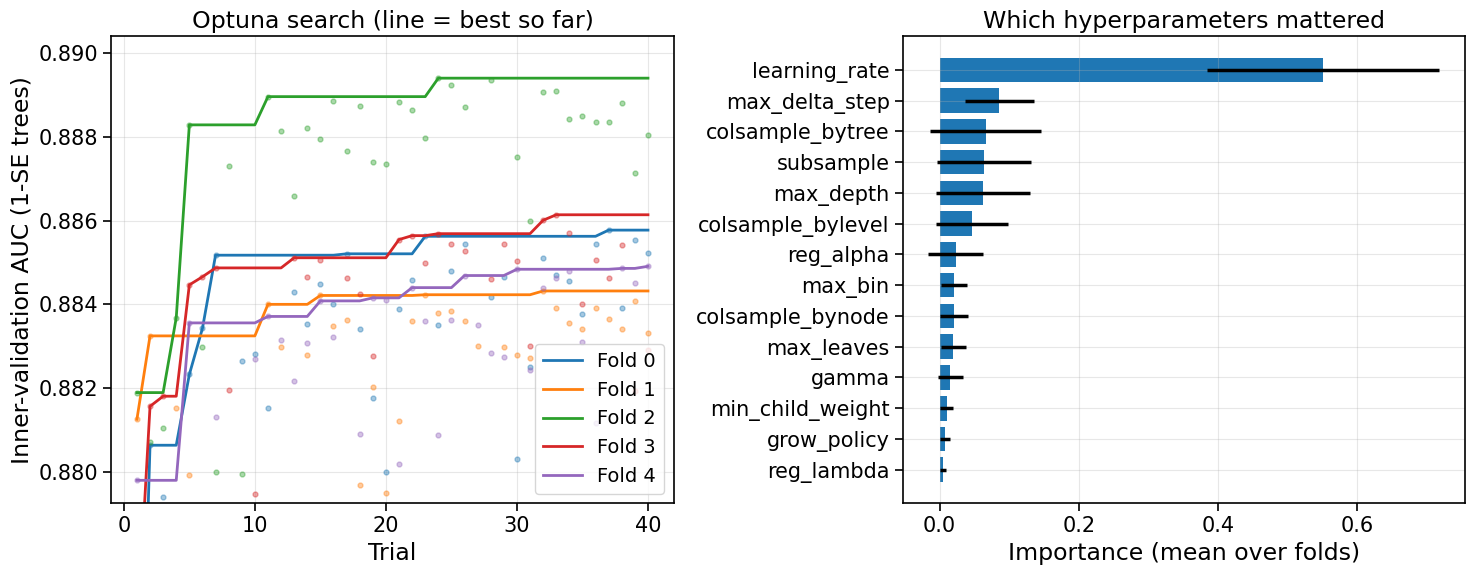

In [9]:
# Did the five folds' searches agree? One column per fold: its winning settings and scores. Similar settings mean
# a stable optimum; very different settings with similar scores mean the AUC is flat in those directions (they
# don't matter). The inner-validation AUC is the best of N_TRIALS trials on the set used to choose them, so it is
# optimistic; the held-out AUC (events no choice ever used) is the honest one, and the difference is the tuning optimism.
held_out_auc = [roc_auc_score(pre.loc[pre["fold"] == k, "is_sig"], pre.loc[pre["fold"] == k, "bdt_kfold"],
                              sample_weight=pre.loc[pre["fold"] == k, WGT]) for k in range(K)]
fold_table = pd.DataFrame({f"fold {k}": {**r["params"], "min-loss trees": r["best_trees"], "1-SE trees": r["n_trees"],
                                         "train AUC": r["train_auc"], "inner-val AUC": r["inner_val_auc"],
                                         "held-out AUC": held_out_auc[k]}
                           for k, r in enumerate(fold_results)})
with pd.option_context("display.float_format", "{:.4g}".format):
    display(fold_table)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
# Left: every trial's score (points) and the best so far (line), per fold
all_values = []
for k, r in enumerate(fold_results):
    h = np.array(r["history"], dtype=float)   # failed trials (None) become NaN
    trial_no = np.arange(1, len(h) + 1)
    ax1.plot(trial_no, h, ".", color=f"C{k}", alpha=0.4)
    ax1.plot(trial_no, np.fmax.accumulate(h), color=f"C{k}", lw=2, label=f"Fold {k}")
    all_values.extend(h)
ax1.set_ylim(np.nanquantile(all_values, 0.25) - 0.002, np.nanmax(all_values) + 0.001)
ax1.set_xlabel("Trial")
ax1.set_ylabel("Inner-validation AUC (1-SE trees)")
ax1.set_title("Optuna search (line = best so far)")
ax1.legend(loc="lower right")
# Right: how much each hyperparameter mattered (Optuna's importance), mean over folds, error bars = spread
imp = pd.DataFrame([r["importance"] for r in fold_results]).fillna(0)
order = imp.mean().sort_values()
ax2.barh(order.index, order, xerr=imp.std()[order.index])
ax2.set_xlabel("Importance (mean over folds)")
ax2.set_title("Which hyperparameters mattered")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Visualise overfitting as a function of trees, for every fold's final model (inner training vs inner validation, the sets its tree count was chosen on). The earlier single 80:20-split version of this plot is saved in `figures/learning_curve_single_split_80-20.png`.

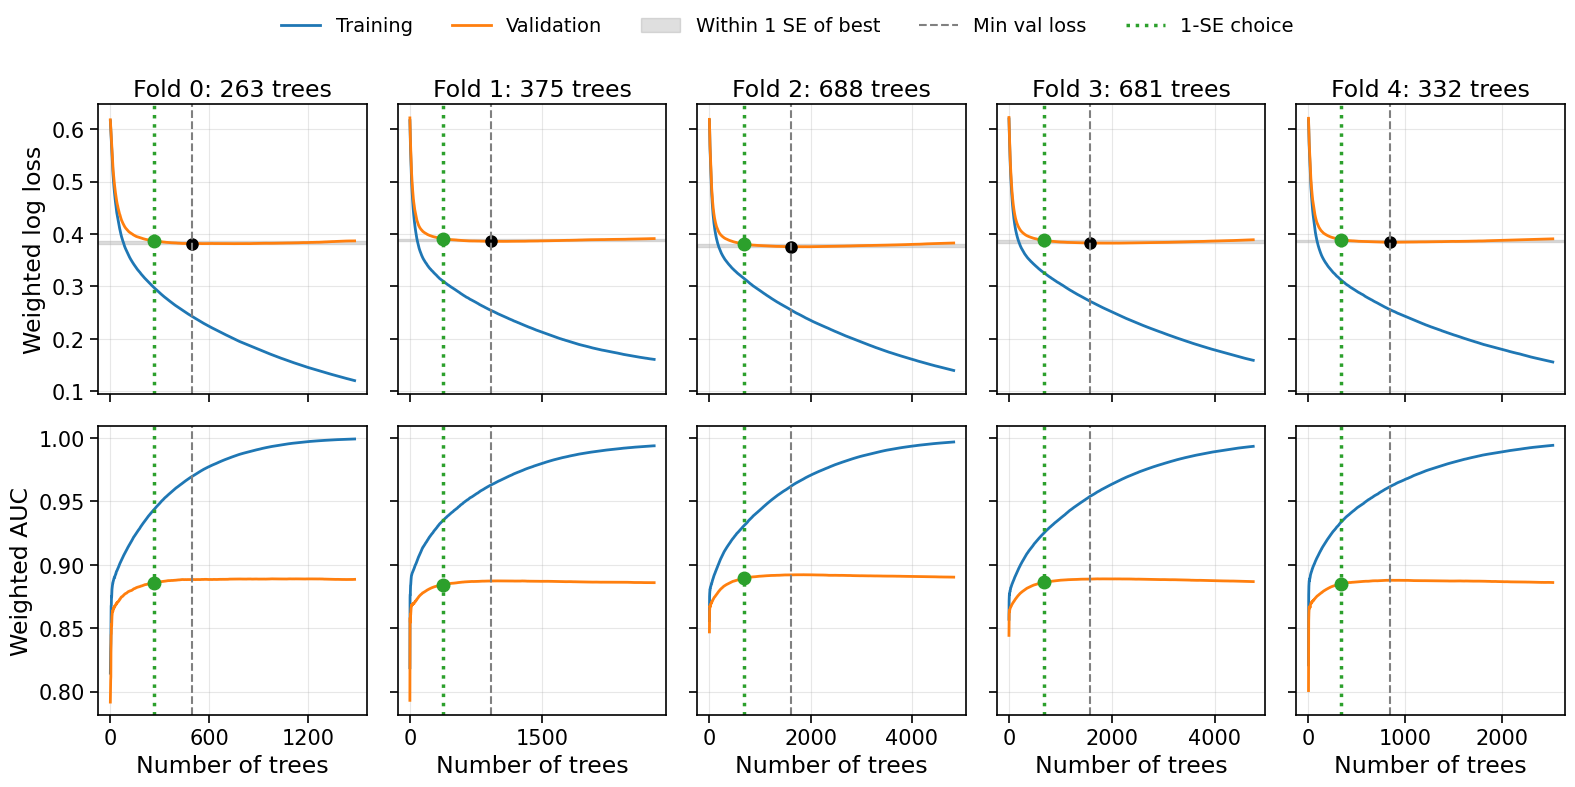

      min-loss trees  1-SE trees      SE  val loss at min  val loss at 1-SE  val - train loss gap at 1-SE  max val AUC  trees at max val AUC  val AUC at 1-SE
fold                                                                                                                                                         
0                494         263  0.0053           0.3816            0.3869                        0.0883       0.8890                   979           0.8858
1                925         375  0.0052           0.3859            0.3911                        0.0807       0.8873                  1091           0.8843
2               1608         688  0.0051           0.3757            0.3807                        0.0660       0.8922                  1781           0.8894
3               1582         681  0.0051           0.3826            0.3877                        0.0618       0.8889                  1727           0.8861
4                841         332  0.0054           0

In [10]:
# Learning curves for each fold: log loss and AUC on the inner training and inner validation sets after every tree,
# trained well past the best point to show where overfitting starts. Grey band = within 1 SE of the minimum
# inner-validation loss; black point = the minimum (where early stopping lands); green point = the 1-SE choice used.
# The numbers behind each panel are in the table printed below the plot.
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(2, K, figsize=(16, 8), sharex="col", sharey="row")
summary_rows = []
for k, c in enumerate(curves):
    trees = np.arange(1, len(c["train loss"]) + 1)
    b, n = c["best"], c["n_1se"]
    ax1, ax2 = axes[0, k], axes[1, k]

    # Top: log loss against number of trees
    ax1.plot(trees, c["train loss"], lw=2, label="Training")
    ax1.plot(trees, c["val loss"], lw=2, label="Validation")
    ax1.axhspan(c["val loss"][b - 1], c["val loss"][b - 1] + c["se"], color="grey", alpha=0.25,
                label="Within 1 SE of best")
    ax1.plot(b, c["val loss"][b - 1], "ko", markersize=8)
    ax1.plot(n, c["val loss"][n - 1], "o", color="C2", markersize=9)
    ax1.set_title(f"Fold {k}: {n} trees")

    # Bottom: AUC against number of trees
    ax2.plot(trees, c["train auc"], lw=2, label="Training")
    ax2.plot(trees, c["val auc"], lw=2, label="Validation")
    ax2.plot(n, c["val auc"][n - 1], "o", color="C2", markersize=9)
    ax2.set_xlabel("Number of trees")
    ax2.xaxis.set_major_locator(MaxNLocator(3))

    for ax in (ax1, ax2):
        ax.axvline(b, color="grey", ls="--", lw=1.5, label="Min val loss")
        ax.axvline(n, color="C2", ls=":", lw=2.5, label="1-SE choice")
        ax.grid(alpha=0.3)
    summary_rows.append({"fold": k, "min-loss trees": b, "1-SE trees": n, "SE": c["se"],
                         "val loss at min": c["val loss"][b - 1], "val loss at 1-SE": c["val loss"][n - 1],
                         "val - train loss gap at 1-SE": c["val loss"][n - 1] - c["train loss"][n - 1],
                         "max val AUC": c["val auc"].max(), "trees at max val AUC": c["val auc"].argmax() + 1,
                         "val AUC at 1-SE": c["val auc"][n - 1]})
axes[0, 0].set_ylabel("Weighted log loss")
axes[1, 0].set_ylabel("Weighted AUC")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

print(pd.DataFrame(summary_rows).set_index("fold").round(4).to_string())

In [11]:
# Losses for the k-fold models.
# Out-of-fold loss: one number over all simulated events using their out-of-fold scores (the honest one).
# Per fold: each model's loss on the events it trained on vs the fold it never saw (the gap = overfitting).
oof_loss = log_loss(y, pre["bdt_kfold"], sample_weight=w_fit)

val_losses, train_losses = [], []
for k, m in enumerate(models):
    out = pre["fold"] == k   # the fold model k never saw
    val_losses.append(log_loss(y[out], pre.loc[out, "bdt_kfold"], sample_weight=w_fit[out]))
    train_losses.append(log_loss(y[~out], m.predict_proba(X[~out])[:, 1], sample_weight=w_fit[~out]))
    print(f"Fold {k}: train {train_losses[-1]:.4f}, held-out {val_losses[-1]:.4f}")

print(f"\nOut-of-fold log loss (all events): {oof_loss:.4f}")
print(f"Held-out loss per fold: {np.mean(val_losses):.4f} ± {np.std(val_losses):.4f}")
print(f"Training loss per fold: {np.mean(train_losses):.4f} ± {np.std(train_losses):.4f}")

Fold 0: train 0.3162, held-out 0.3851


Fold 1: train 0.3267, held-out 0.3785


Fold 2: train 0.3278, held-out 0.3914


Fold 3: train 0.3382, held-out 0.3805


Fold 4: train 0.3282, held-out 0.3838

Out-of-fold log loss (all events): 0.3838
Held-out loss per fold: 0.3838 ± 0.0044
Training loss per fold: 0.3274 ± 0.0070


9: Check for overtraining (fold-0 model: events it trained on vs the fold it never saw)

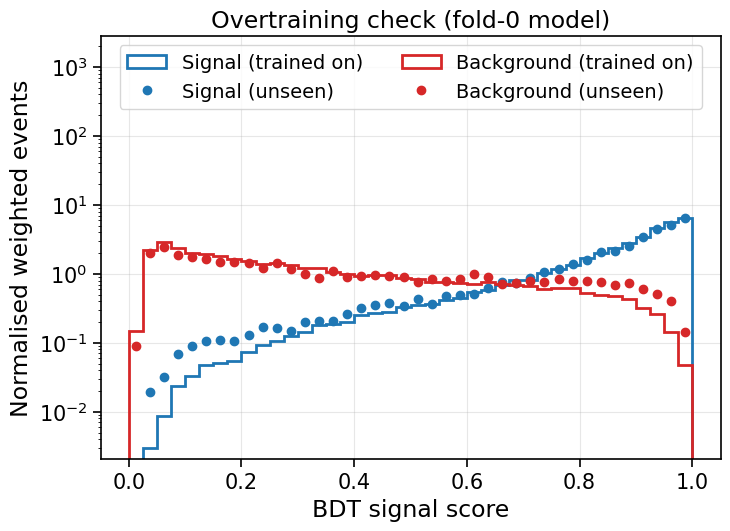

In [12]:
# Overtraining check: score every simulated event with the fold-0 model, then compare the score
# distributions of events it trained on (lines) and events it never saw (points). If they match,
# the model behaves the same on new events.
score0 = pd.Series(models[0].predict_proba(X)[:, 1], index=pre.index)
seen = pre["fold"] != 0   # events the fold-0 model trained on (incl. its inner-validation subset)

bins = np.linspace(0, 1, 41)
centres = (bins[:-1] + bins[1:]) / 2

for sig, colour, name in [(1, "C0", "Signal"), (0, "C3", "Background")]:
    train = seen & (pre["is_sig"] == sig)
    test = ~seen & (pre["is_sig"] == sig)
    plt.hist(score0[train], bins=bins, weights=pre.loc[train, WGT], density=True,
             histtype="step", lw=2, color=colour, label=f"{name} (trained on)")
    h, _ = np.histogram(score0[test], bins=bins, weights=pre.loc[test, WGT], density=True)
    plt.plot(centres, h, "o", color=colour, markersize=6, label=f"{name} (unseen)")

plt.yscale("log")
plt.xlabel("BDT signal score")
plt.ylabel("Normalised weighted events")
plt.title("Overtraining check (fold-0 model)")
plt.ylim(top=plt.ylim()[1] * 300)   # headroom above the curves for the legend
plt.legend(loc="upper center", ncol=2)
plt.grid(alpha=0.3)
plt.show()

10: ROC curve (out-of-fold scores, all simulated events)

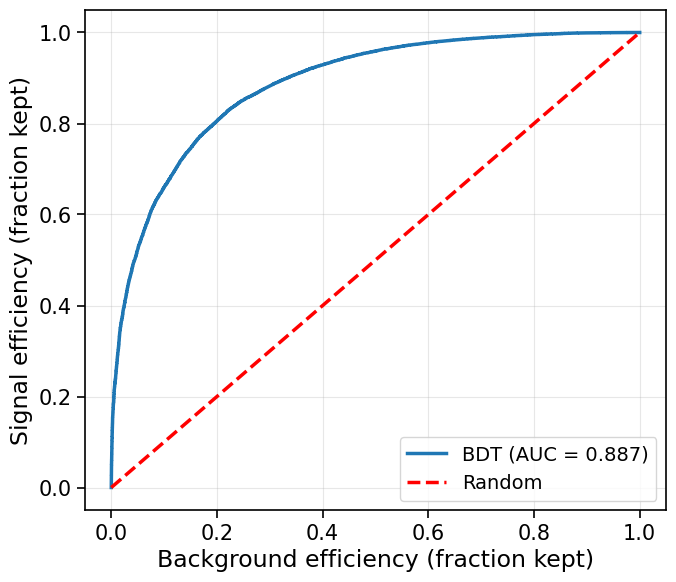

In [13]:
# ROC curve: for every possible BDT threshold, the fraction of signal kept (y) against the fraction of
# background kept (x), from the out-of-fold scores of all simulated events, using event weights.
bkg_eff, sig_eff, _ = roc_curve(pre["is_sig"], pre["bdt_kfold"], sample_weight=pre[WGT])
auc = roc_auc_score(pre["is_sig"], pre["bdt_kfold"], sample_weight=pre[WGT])

plt.figure(figsize=(7.5, 6.5))
plt.plot(bkg_eff, sig_eff, label=f"BDT (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "r--", label="Random")
plt.xlabel("Background efficiency (fraction kept)")
plt.ylabel("Signal efficiency (fraction kept)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

11: Feature importance (mean gain across the k-fold models; error bars = spread between folds)

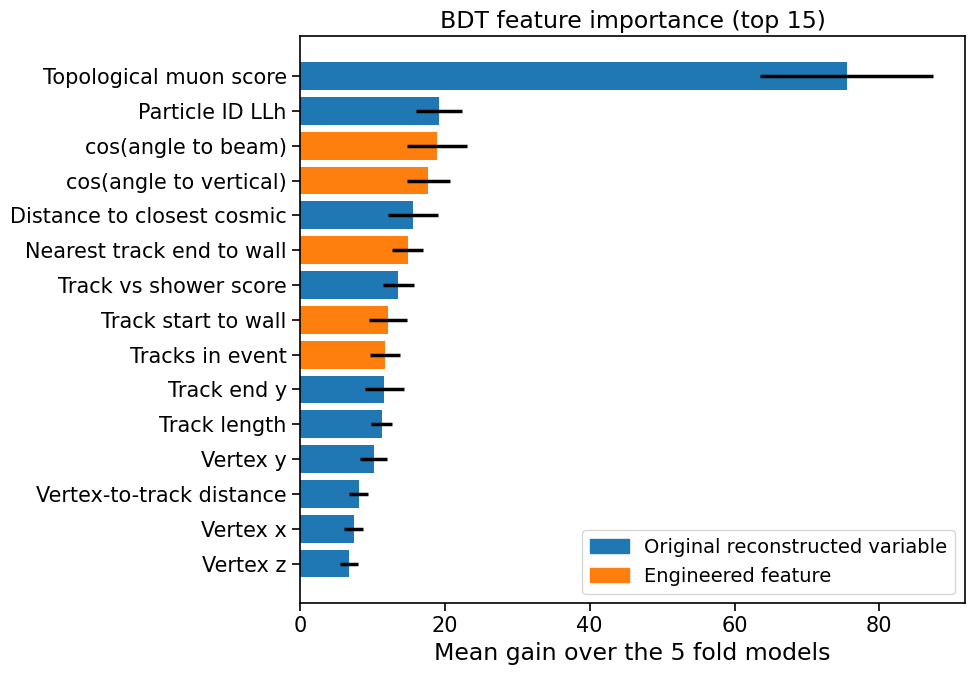

In [14]:
# Feature importance: average "gain" (how much each feature improves the trees' splits) over the 5 k-fold
# models; error bars show how much the 5 models disagree. Engineered features (ENGINEERED, from the setup cell)
# are shown in orange, the original reconstructed variables in blue.
from matplotlib.patches import Patch

gain = pd.DataFrame([m.get_booster().get_score(importance_type="gain") for m in models]).fillna(0)
top = gain.mean().sort_values().tail(15)
colours = ["tab:orange" if f in ENGINEERED else "tab:blue" for f in top.index]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh([LABELS.get(f, f) for f in top.index], top, xerr=gain.std()[top.index], color=colours)
ax.legend(handles=[Patch(color="tab:blue", label="Original reconstructed variable"),
                   Patch(color="tab:orange", label="Engineered feature")], loc="lower right")
ax.set_xlabel("Mean gain over the 5 fold models")
ax.set_title("BDT feature importance (top 15)")
plt.tight_layout()
plt.show()


12: Check weight normalisation

In [15]:
# First use of the REAL data. Compare the expected number of preselected events from simulation
# (sum of weights) with the number of real preselected events: they should be similar if the weights
# are normalised to the data's exposure.
data = load("Data.pkl")   # all real candidate rows, before any selection
print("Simulation (weighted, after preselection):", pre[WGT].sum())
print("Data events (after preselection):", len(preselect(data)))

Simulation (weighted, after preselection): 18453.835037635512
Data events (after preselection): 19877


13a. Threshold scan: maximise S/√(S+B), i.e. efficiency × purity (the cut used from here on)

cut                 0.400000
S               11909.741237
B                2576.630589
efficiency          0.943893
purity              0.822134
significance       98.951530
Name: 40, dtype: float64


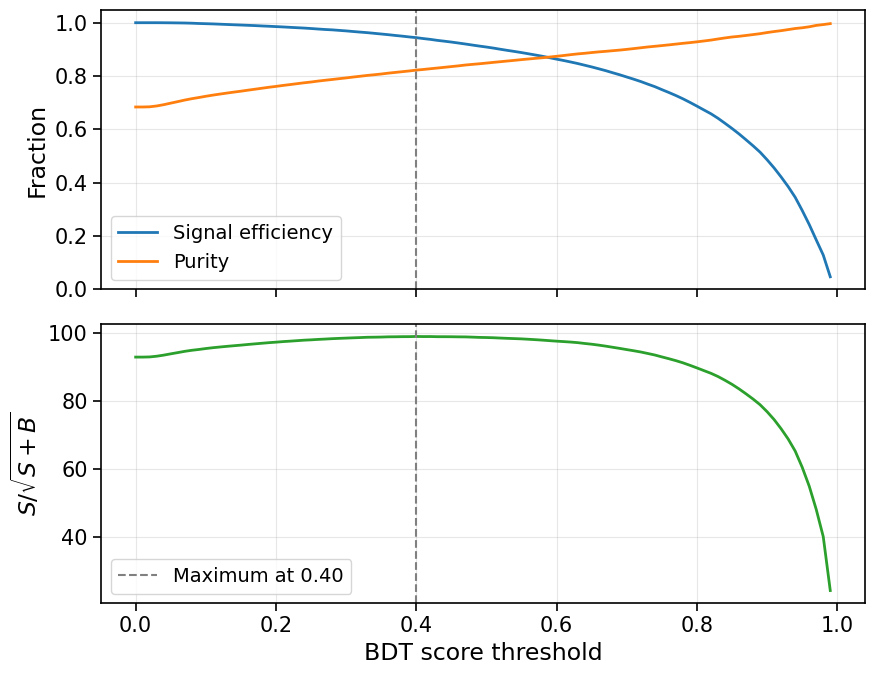

In [16]:
# Choose the BDT threshold on simulation only. For each threshold, add up the weights of signal (S) and
# background (B) passing it, and find the threshold that maximises S/sqrt(S+B).
# (S/√(S+B))² = S_tot · efficiency · purity, so this is also the cut that maximises efficiency × purity.
# It is the cut used from here on (BEST_CUT, set at the end of the next cell); the expected-sensitivity
# choice in the next cell is kept for comparison.
# Every simulated event has an out-of-fold score, so S and B are already full-sample numbers
S_tot = pre.loc[pre["is_sig"] == 1, WGT].sum()
rows = []
for cut in np.linspace(0, 0.99, 100):
    passed = pre[pre["bdt_kfold"] > cut]
    S = passed.loc[passed["is_sig"] == 1, WGT].sum()
    B = passed.loc[passed["is_sig"] == 0, WGT].sum()
    N = S + B
    rows.append({"cut": cut, "S": S, "B": B,
                 "efficiency": S / S_tot,
                 "purity": S / N if N > 0 else np.nan,
                 "significance": S / np.sqrt(N) if N > 0 else np.nan})

sig_scan = pd.DataFrame(rows)
CUT_SIGNIFICANCE = sig_scan.loc[sig_scan["significance"].idxmax(), "cut"]   # becomes BEST_CUT (see next cell)
print(sig_scan.loc[sig_scan["significance"].idxmax()])

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
ax1.plot(sig_scan["cut"], sig_scan["efficiency"], lw=2, label="Signal efficiency")
ax1.plot(sig_scan["cut"], sig_scan["purity"], lw=2, label="Purity")
ax1.set_ylabel("Fraction")
ax1.legend()
ax2.plot(sig_scan["cut"], sig_scan["significance"], lw=2, color="C2")
ax2.set_ylabel(r"$S/\sqrt{S+B}$")
ax2.set_xlabel("BDT score threshold")
for ax in (ax1, ax2):
    ax.axvline(CUT_SIGNIFICANCE, color="grey", ls="--", lw=1.5, label=f"Maximum at {CUT_SIGNIFICANCE:.2f}")
    ax.grid(alpha=0.3)
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [ ]:
# The threshold scan above on its own (for slides, no title)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 7.5))
ax1.plot(sig_scan["cut"], sig_scan["efficiency"], lw=2.5, label="Signal efficiency")
ax1.plot(sig_scan["cut"], sig_scan["purity"], lw=2.5, label="Purity")
ax1.set_ylabel("Fraction")
ax2.plot(sig_scan["cut"], sig_scan["significance"], lw=2.5, color="C2")
ax2.set_ylabel(r"$S/\sqrt{S+B}$")
ax2.set_xlabel("BDT score threshold")
for ax in (ax1, ax2):
    ax.axvline(CUT_SIGNIFICANCE, color="grey", ls="--", lw=2, label=f"Maximum at {CUT_SIGNIFICANCE:.2f}")
    ax.grid(alpha=0.3)
ax1.legend(loc="lower left")
ax2.legend(loc="lower left")
ax2.set_xlim(0, 1)
plt.tight_layout()
fig.savefig("figures/efficiency_purity_threshold_scan.png")
plt.show()


13b. Choose the cut by expected sensitivity (simulation only)

For each candidate cut, the selected **Simulation.pkl** events (`pre`, with out-of-fold scores) are used twice:
their no-oscillation energy spectrum is the "pretend data" (a world with no sterile neutrino, so no dip), and the
same events reweighted by the survival probability give each hypothetical sterile neutrino. At each Δm² the
smallest sin²2θ whose dip differs from the pretend data by Δχ² = 4.61 (90% CL, two parameters) is the
**expected exclusion line** for that cut, using the same χ² as the fit (statistics, 15% systematic, simulation
statistics). Neither Data.pkl nor OscillatedSimulation.pkl is used.

How to choose graphically:
1. **Left plot:** the line that reaches furthest **left** detects the smallest dips, so it is the best cut.
   Pay most attention around Δm² ≈ 1 eV² (dashed line): that is where the experiment is most sensitive
   and where LSND and MiniBooNE sit.
2. **Right plot:** the expected limit at 1 eV² against the cut is usually U-shaped (too loose: background
   dilutes the dip; too tight: too few events). Choose the **bottom of the U**. If the bottom is flat,
   any cut in the flat region is equally good; pick the middle of it.
3. **Table:** check the best cut is similar at the other reference Δm² values. If the lines cross, the rule
   decided in advance (best at 1 eV²) decides.

**Comparison only:** the cut used (`BEST_CUT`) is the efficiency × purity maximum from 13a. Set `CHOSEN_CUT` to override it. Every later cell uses `BEST_CUT`.

In [ ]:
# Choose the BDT cut by EXPECTED SENSITIVITY, using simulation only (pre = preselected Simulation.pkl with
# out-of-fold scores). For each candidate cut:
#   1. select the simulated events above the cut;
#   2. "pretend data" = their no-oscillation energy spectrum (no sterile neutrino, so no dip);
#   3. reweight the same events for each (Δm², sin²2θ) and find, at each Δm², the smallest sin²2θ whose dip
#      differs from the pretend data by Δχ² = 4.61 (90% CL, two parameters) -> the expected exclusion line.
from scipy.optimize import brentq

CANDIDATE_CUTS = [0.2, 0.38, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]   # lines drawn on the left plot (edit freely)
REF_DM2 = [0.3, 1.0, 3.0, 10.0]                                      # Δm² values (eV²) for the table
CHOSEN_CUT = None          # set to a number (e.g. 0.85) after looking at the plots; None = automatic choice
CUT_SYST = 0.15            # same 15% per-bin systematic as the fit
# NOTE (to do later): the cut is chosen with 15% only. The systematic-size test at the end of the notebook
# varies the FIT's systematic with this cut held fixed; consider also re-choosing the cut with CUT_SYST set
# to each tested value, to see whether a different systematic would favour a looser or tighter cut.
L_CUT = 0.47               # baseline in km, as in predict()
dm2_lines = np.logspace(-1, 2, 40)

def p_survive(E, dm2, s22t):
    return 1 - s22t * np.sin(1.27 * dm2 * L_CUT / E) ** 2

def merge_to_min(edges, counts, min_count=20):
    """Merge adjacent bins, low to high energy, until each holds at least min_count."""
    out, acc = [edges[0]], 0.0
    for c, right in zip(counts, edges[1:]):
        acc += c
        if acc >= min_count:
            out.append(right)
            acc = 0.0
    if acc > 0:
        out[-1] = edges[-1]
    return np.array(out)

# One binning for every cut: 0.1 GeV bins (plus overflow), merged so that even the TIGHTEST candidate has
# >= 20 expected events per bin. All cuts are then compared on the same footing.
fine = np.r_[np.linspace(0, 3, 31), 100]
tightest = pre[pre["bdt_kfold"] > max(CANDIDATE_CUTS)]
cut_edges = merge_to_min(fine, np.histogram(tightest[ENERGY], bins=fine, weights=tightest[WGT])[0])
nb_cut = len(cut_edges) - 1

def expected_limits(cut, dm2_values, edges=None):
    """Expected 90% CL limit on sin²2θ at each Δm² (NaN where even full mixing can't be excluded).
    edges: reconstructed-energy binning; default cut_edges, the one binning shared by every candidate cut."""
    edges = cut_edges if edges is None else edges
    nb = len(edges) - 1
    s = pre[pre["bdt_kfold"] > cut]
    idx = np.digitize(s[ENERGY], edges) - 1
    w0 = s[WGT].to_numpy()
    osc = (s[CAT] != 7).to_numpy()                      # same rule as predict(): everything except beam-off
    Et = s["Simulated neutrino energy"].to_numpy()
    asimov = np.bincount(idx, weights=w0, minlength=nb)    # pretend data: no oscillation

    def dchi2(dm2, s22t):
        w = w0.copy()
        w[osc] *= p_survive(Et[osc], dm2, s22t)               # only beam-neutrino events oscillate
        pred = np.bincount(idx, weights=w, minlength=nb)
        var = pred + (CUT_SYST * pred) ** 2 + np.bincount(idx, weights=w ** 2, minlength=nb)
        return np.sum((asimov - pred) ** 2 / var)

    lims = []
    for dm2 in dm2_values:
        if dchi2(dm2, 1.0) < 4.61:
            lims.append(np.nan)
        else:
            lims.append(brentq(lambda x: dchi2(dm2, x) - 4.61, 1e-5, 1.0))
    return np.array(lims)

def purity_efficiency(cut):
    passed = pre[pre["bdt_kfold"] > cut]
    S = passed.loc[passed["is_sig"] == 1, WGT].sum()
    B = passed.loc[passed["is_sig"] == 0, WGT].sum()
    return S / (S + B), S / sig_pre, S / sig_all, S + B

# Lines and table for the candidate cuts
rows, lines = [], {}
for cut in CANDIDATE_CUTS:
    pur, eff, eff_all, n_sel = purity_efficiency(cut)
    lines[cut] = expected_limits(cut, dm2_lines)
    row = {"cut": cut, "purity": pur, "efficiency": eff, "efficiency incl. presel.": eff_all,
           "selected (weighted)": n_sel}
    row.update({f"limit @ {d:g} eV²": v for d, v in zip(REF_DM2, expected_limits(cut, REF_DM2))})
    rows.append(row)
cut_table = pd.DataFrame(rows).set_index("cut")
print("Expected 90% CL limits on sin²2θ (smaller = better) with purity and efficiency for each cut:")
print(cut_table.round(3).to_string())

# Finer scan at 1 eV² for the U-shaped curve
u_cuts = np.round(np.arange(0.1, max(CANDIDATE_CUTS) + 1e-9, 0.025), 3)
u_lims = np.array([expected_limits(c, [1.0])[0] for c in u_cuts])
u_pur = np.array([purity_efficiency(c)[0] for c in u_cuts])
recommended = u_cuts[np.nanargmin(u_lims)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(CANDIDATE_CUTS)))
for cut, col in zip(CANDIDATE_CUTS, colours):
    ax1.plot(lines[cut], dm2_lines, color=col, lw=2,
             label=f"{cut:.2f}  ({cut_table.loc[cut, 'purity']:.0%}, {cut_table.loc[cut, 'efficiency']:.0%})")
ax1.axhline(1.0, color="grey", ls="--", lw=1)

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlim(1e-2, 1)
ax1.set_ylim(dm2_lines[0], dm2_lines[-1])
ax1.set_xlabel(r"sin$^2 2\theta$")
ax1.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax1.set_title("Expected 90% CL exclusion for each cut\n(further left = detects smaller dips)")
ax1.legend(loc="lower left", title="Cut (purity, efficiency)")
ax1.grid(alpha=0.3, which="both")

ax2.plot(u_cuts, u_lims, "o-", color="C0", lw=2, markersize=6)
ax2.axvline(recommended, color="C3", ls="--", lw=2, label=f"Smallest limit: cut {recommended:.3f}")
ax2.set_xlabel("BDT cut")
ax2.set_ylabel(r"Expected 90% CL limit on sin$^2 2\theta$")
ax2.set_title("Expected limit at $\\Delta m^2$ = 1 eV$^2$\n(lower = better: choose the bottom of the U)")
ax2.grid(alpha=0.3)
ax2.legend(loc="upper center")
ax3 = ax2.twinx()
ax3.plot(u_cuts, u_pur, color="grey", ls=":", lw=2.5)
ax3.set_ylabel("Purity (dotted)", color="grey")
plt.tight_layout()
plt.show()

# Cut used by every later cell: the efficiency × purity maximum from 13a (CUT_SIGNIFICANCE); the expected-
# sensitivity minimum (recommended) is printed for comparison only
BEST_CUT = CUT_SIGNIFICANCE if CHOSEN_CUT is None else CHOSEN_CUT
pur, eff, eff_all, n_sel = purity_efficiency(BEST_CUT)
print(f"Expected-sensitivity choice (smallest expected limit at 1 eV², comparison only): {recommended:.3f}")
print(f"Cut used from here on: BEST_CUT = {BEST_CUT:.3f} -> purity {pur:.3f}, efficiency {eff:.3f} "
      f"({eff_all:.3f} including preselection)")
print(f"(= the efficiency × purity maximum from 13a, i.e. the S/√(S+B) maximum)")

In [ ]:
# Threshold scan on one set of axes (for slides, no title). efficiency × purity = (S/√(S+B))² / S_tot, so it
# peaks at the same cut as S/√(S+B) and fits on the same 0–1 axis as efficiency and purity.
# The chosen cut (0.40) is marked, with the efficiency and purity where its line crosses those curves.
eff_pur = sig_scan["efficiency"] * sig_scan["purity"]
assert np.isclose(sig_scan.loc[eff_pur.idxmax(), "cut"], CUT_SIGNIFICANCE)
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.plot(sig_scan["cut"], sig_scan["efficiency"], lw=2.5, color="C0", label="Signal efficiency")
ax.plot(sig_scan["cut"], sig_scan["purity"], lw=2.5, color="C1", label="Purity")
ax.plot(sig_scan["cut"], eff_pur, lw=2.5, color="C2", label="Efficiency × purity")
ax.axvline(CUT_SIGNIFICANCE, color="grey", ls="--", lw=2, label=f"Maximum at {CUT_SIGNIFICANCE:.2f}")
# (offset in points, ha, va) for each label, chosen to keep clear of the curves
LABELS = {"efficiency": ((10, 8), "left", "bottom"), "purity": ((-10, 8), "right", "bottom")}
for col_name, (xy, ha, va) in LABELS.items():
    col = "C0" if col_name == "efficiency" else "C1"
    y = np.interp(CUT_SIGNIFICANCE, sig_scan["cut"], sig_scan[col_name])
    ax.plot(CUT_SIGNIFICANCE, y, "o", color=col, markersize=10, markeredgecolor="white", markeredgewidth=1.5, zorder=5)
    ax.annotate(f"{col_name} {y:.1%}", (CUT_SIGNIFICANCE, y), xytext=xy, textcoords="offset points", ha=ha, va=va,
                fontsize=14, fontweight="bold", color=col,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=col, lw=1.5), zorder=6)
ax.set_xlabel("BDT score threshold")
ax.set_ylabel("Fraction")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("figures/efficiency_purity_threshold_scan_single.png")
plt.show()


In [ ]:
# Expected 90% CL exclusion line for each candidate cut, on its own (for slides, no title).
# Further left = sensitive to smaller dips. Darker colour scale than above so the tight cuts show on a white slide.
fig, ax = plt.subplots(figsize=(10, 7.5))
colours = plt.cm.plasma(np.linspace(0, 0.85, len(CANDIDATE_CUTS)))
for cut, col in zip(CANDIDATE_CUTS, colours):
    ax.plot(lines[cut], dm2_lines, color=col, lw=2.5,
            label=f"{cut:.2f}  ({cut_table.loc[cut, 'purity']:.0%}, {cut_table.loc[cut, 'efficiency']:.0%})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-2, 1)
ax.set_ylim(dm2_lines[0], dm2_lines[-1])
ax.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$")
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax.legend(loc="lower left", title="Cut (purity, efficiency)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig("figures/expected_exclusion_per_cut.png")
plt.show()


In [ ]:
# Expected 90% CL exclusion line for the chosen cut (0.40), with the range of cuts that are as sensitive
# (for slides, no title). Further left = sensitive to smaller dips.
# Each cut uses its OWN binning (0.1 GeV bins merged on that cut's selection to >= 20 events, as fit_edges is for the
# fit), so the 0.40 numbers match the fit's expected limits. (The shared cut_edges of 13b merge away the low-energy
# bins that the loose cuts have plenty of events in, which made tight cuts look better than they are.)
# Range: the cuts whose expected limit is within 5% of the best at every marked Δm² (0.5, 1, 3, 10 eV²). Its two
# edges are drawn and the region between them shaded: the sensitivity is flat across it, so it doesn't pick a cut.
# The marked points are the 0.40 limits at those fixed Δm² values (dotted lines); under each, in grey, the range of
# expected limits over all the cuts in the band (the edge lines alone sit almost on top of the 0.40 line).
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def own_edges(cut):
    """The fit's binning rule applied to one cut's selection (own_edges(BEST_CUT) is fit_edges)."""
    s = pre[pre["bdt_kfold"] > cut]
    return merge_to_min(fine, np.histogram(s[ENERGY], bins=fine, weights=s[WGT])[0])

PT_DM2 = [0.5, 1.0, 3.0, 10.0]
own_scan = np.array([expected_limits(c, PT_DM2, own_edges(c)) for c in u_cuts])   # every cut of the 13b scan
near_best = u_cuts[np.all(own_scan <= 1.05 * np.nanmin(own_scan, axis=0), axis=1)]
CUT_LO, CUT_HI = near_best.min(), near_best.max()
in_band = (u_cuts >= CUT_LO) & (u_cuts <= CUT_HI)
BAND_MIN, BAND_MAX = np.nanmin(own_scan[in_band], axis=0), np.nanmax(own_scan[in_band], axis=0)   # per Δm²
print(f"Cuts within 5% of the best expected limit at every Δm² (own binning): {CUT_LO:.3f}-{CUT_HI:.3f}")
for c in (CUT_LO, BEST_CUT, CUT_HI):
    print(f"  cut {c:.3f}: " + ", ".join(f"{v:.3f} at {d:g} eV²"
                                        for d, v in zip(PT_DM2, expected_limits(c, PT_DM2, own_edges(c)))))
print("  range over the band: " + ", ".join(f"{a:.3f}-{b:.3f} at {d:g} eV²" for d, a, b in zip(PT_DM2, BAND_MIN, BAND_MAX)))
print("  best:      " + ", ".join(f"{v:.3f} at {d:g} eV²" for d, v in zip(PT_DM2, np.nanmin(own_scan, axis=0))))

fig, ax = plt.subplots(figsize=(10, 7.5))
for d in PT_DM2:
    ax.axhline(d, color="grey", ls=":", lw=1.8, zorder=1)
    ax.annotate(rf"$\Delta m^2$ = {d:g} eV$^2$", (0.0105, d), xytext=(0, 4), textcoords="offset points",
                va="bottom", fontsize=14, color="dimgrey")
x_lo, x_hi = (expected_limits(c, dm2_lines, own_edges(c)) for c in (CUT_LO, CUT_HI))
ax.fill_betweenx(dm2_lines, x_lo, x_hi, color="grey", alpha=0.3, lw=0)
ax.plot(x_lo, dm2_lines, color="dimgrey", ls="--", lw=1.8)
ax.plot(x_hi, dm2_lines, color="dimgrey", ls="-.", lw=1.8)
pur, eff = purity_efficiency(BEST_CUT)[:2]
edges = own_edges(BEST_CUT)
ax.plot(expected_limits(BEST_CUT, dm2_lines, edges), dm2_lines, color="C0", lw=2.5)
pts = expected_limits(BEST_CUT, PT_DM2, edges)
ax.plot(pts, PT_DM2, "o", color="C0", markersize=11, markeredgecolor="white", markeredgewidth=1.5, zorder=5)
for s, d, lo, hi in zip(pts, PT_DM2, BAND_MIN, BAND_MAX):
    ax.annotate(f"{s:.3f}", (s, d), xytext=(-14, 2), textcoords="offset points", ha="right", va="bottom",
                fontsize=15, fontweight="bold", color="C0",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="C0", lw=1.5), zorder=6)
    ax.annotate(f"{lo:.3f}–{hi:.3f}", (s, d), xytext=(-14, -2), textcoords="offset points", ha="right", va="top",
                fontsize=13, color="dimgrey", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="grey", lw=1),
                zorder=6)
handles = [Line2D([], [], color="C0", lw=2.5, marker="o", markersize=11, markeredgecolor="white",
                  label=f"BDT cut {BEST_CUT:.2f} (max. $S/\\sqrt{{S+B}}$)\npurity {pur:.0%}, efficiency {eff:.0%}"),
           Line2D([], [], color="dimgrey", ls="--", lw=1.8, label=f"Cut {CUT_LO:.2f} (lower bound)"),
           Line2D([], [], color="dimgrey", ls="-.", lw=1.8, label=f"Cut {CUT_HI:.2f} (upper bound)"),
           Patch(facecolor="grey", alpha=0.3, label="Between the bounds: within 5% of best\n(grey numbers: their range of limits)"),
           Line2D([], [], color="grey", ls=":", lw=1.8, label=r"Points: expected limit at a fixed $\Delta m^2$")]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-2, 1)
ax.set_ylim(0.02, dm2_lines[-1])   # room under the lines (they end near 0.4 eV²) for the legend
ax.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$")
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax.legend(handles=handles, loc="lower left")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig("figures/expected_exclusion_two_cuts.png")
plt.show()


In [ ]:
# Is choosing the cut at 1 eV² defensible? Repeat the fine cut scan from 13b at other Δm² and see where each
# minimum lies. Cuts whose expected limit is within 1% of the minimum count as equally good (the flat region).
CHECK_DM2 = [0.5, 1.0, 3.0, 10.0]
check = pd.DataFrame([expected_limits(c, CHECK_DM2) for c in u_cuts], index=u_cuts, columns=CHECK_DM2)
rows = []
for d in CHECK_DM2:
    lim = check[d]
    flat = lim.index[lim <= 1.01 * lim.min()]
    at_best, at_rec = expected_limits(BEST_CUT, [d])[0], expected_limits(recommended, [d])[0]
    rows.append({"Δm² (eV²)": d, "best cut": lim.idxmin(), "limit there": lim.min(),
                 "within 1% of best": f"{flat.min():.3f}–{flat.max():.3f}",
                 f"limit at {BEST_CUT:.2f}": at_best, f"limit at {recommended:.2f}": at_rec,
                 f"{recommended:.2f} better by": f"{1 - at_rec / at_best:.1%}"})
robust = pd.DataFrame(rows).set_index("Δm² (eV²)")
print("Expected 90% CL limit on sin²2θ against the cut, at several Δm² (smaller = better):")
print(robust.round(3).to_string())

# Each Δm²'s limit divided by its own minimum, so all four fit on one axis; 1 = best cut at that Δm²
fig, ax = plt.subplots(figsize=(10, 7.5))
for d, col in zip(CHECK_DM2, plt.cm.plasma(np.linspace(0, 0.85, len(CHECK_DM2)))):
    ax.plot(u_cuts, check[d] / check[d].min(), "o-", color=col, lw=2.5, markersize=6, label=f"$\Delta m^2$ = {d:g} eV$^2$")
ax.axvline(BEST_CUT, color="C0", ls="--", lw=2, label=f"Cut {BEST_CUT:.2f}")
ax.axhline(1.01, color="grey", ls=":", lw=2, label="1% above the minimum")
ax.set_xlabel("BDT cut")
ax.set_ylabel("Expected limit / smallest limit at that $\Delta m^2$")
ax.legend(loc="upper center")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("figures/cut_choice_robustness.png")
plt.show()


14. Which backgrounds survive?

In [18]:
# What the selection is made of: weighted events of each true category before and after the cut
# (simulation only - real data has no categories)
names = {21: "numu CC (signal)", 31: "nu NC", 10: "nue CC",
         7: "EXT (beam off)", 5: "Out of fiducial vol.", 4: "Cosmic mis-ID"}

passed = pre["bdt_kfold"] > BEST_CUT
table = pd.DataFrame({"before cut": pre.groupby(CAT)[WGT].sum(),
                      "after cut": pre[passed].groupby(CAT)[WGT].sum()}).fillna(0)
table["fraction kept"] = table["after cut"] / table["before cut"]
table["share of selection"] = table["after cut"] / table["after cut"].sum()
table.index = table.index.map(lambda c: names.get(c, c))
print(table.round(3))

                      before cut  after cut  fraction kept  share of selection
Simulation category                                                           
Cosmic mis-ID           1399.157    559.713          0.400               0.039
Out of fiducial vol.     639.285    404.442          0.633               0.028
EXT (beam off)          3053.093    970.103          0.318               0.067
nue CC                    27.936     25.995          0.931               0.002
numu CC (signal)       12617.685  11909.741          0.944               0.822
nu NC                    716.679    616.377          0.860               0.043


15. Check the cut doesn't distort the energy spectrum (a flat signal efficiency vs energy means no distortion)

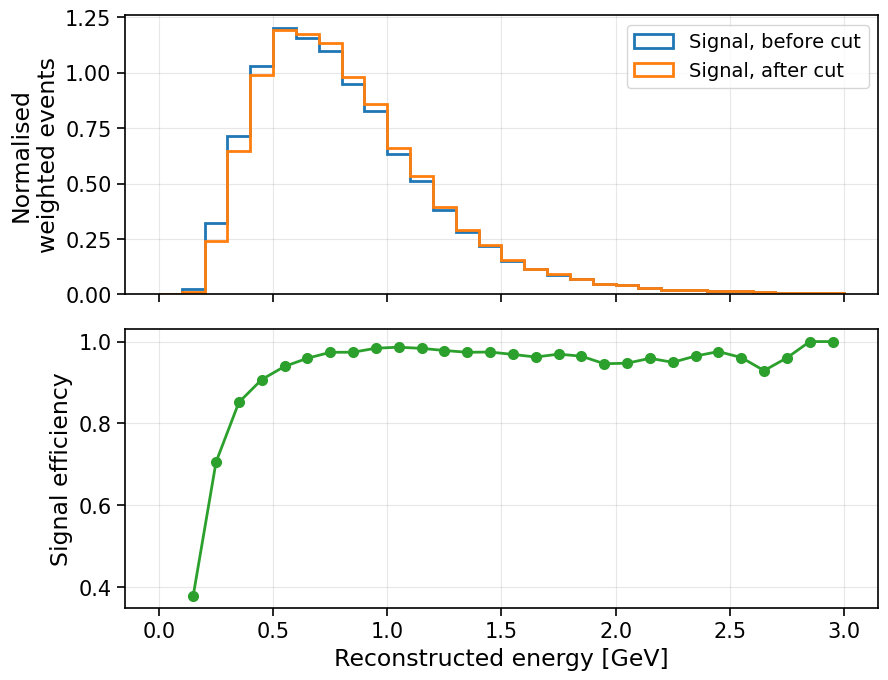

In [19]:
# Does the cut keep signal equally at all energies? Compare the signal's reconstructed-energy spectrum
# before and after the cut (top, shapes only) and the fraction kept in each energy bin (bottom).
# Simulation signal events only.
ebins = np.linspace(0, 3, 31)
ecentres = (ebins[:-1] + ebins[1:]) / 2

sig = pre[pre["is_sig"] == 1]
sig_cut = sig[sig["bdt_kfold"] > BEST_CUT]
h_all, _ = np.histogram(sig[ENERGY], bins=ebins, weights=sig[WGT])
h_cut, _ = np.histogram(sig_cut[ENERGY], bins=ebins, weights=sig_cut[WGT])

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
ax1.hist(sig[ENERGY], bins=ebins, weights=sig[WGT], density=True,
         histtype="step", lw=2, label="Signal, before cut")
ax1.hist(sig_cut[ENERGY], bins=ebins, weights=sig_cut[WGT], density=True,
         histtype="step", lw=2, label="Signal, after cut")
ax1.set_ylabel("Normalised\nweighted events")
ax1.legend()
ax2.plot(ecentres, np.divide(h_cut, h_all, out=np.full_like(h_all, np.nan), where=h_all > 0),
         "o-", lw=2, color="C2")
ax2.set_ylabel("Signal efficiency")
ax2.set_xlabel("Reconstructed energy [GeV]")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Signal efficiency vs reconstructed energy for the chosen cut (for slides): BEST_CUT, the S/√(S+B) maximum.
h_all, _ = np.histogram(sig[ENERGY], bins=ebins, weights=sig[WGT])
fig, ax = plt.subplots(figsize=(9, 6))
for cut, why, col in [(BEST_CUT, r"max. $S/\sqrt{S+B}$", "C0")]:
    sel = sig[sig["bdt_kfold"] > cut]
    h_cut, _ = np.histogram(sel[ENERGY], bins=ebins, weights=sel[WGT])
    eff_total = sel[WGT].sum() / sig[WGT].sum()
    ax.plot(ecentres, np.divide(h_cut, h_all, out=np.full_like(h_all, np.nan), where=h_all > 0), "o-", lw=2.5,
            color=col, label=f"BDT cut {cut:.2f} ({why}): {eff_total:.0%} overall")
ax.set_xlabel("Reconstructed energy [GeV]")
ax.set_ylabel("Signal efficiency")
ax.set_xlim(0, 3)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("figures/signal_efficiency_vs_energy_two_cuts.png")
plt.show()


In [ ]:
# The three cut plots side by side for one slide (no titles): threshold scan with the chosen cut marked, signal
# efficiency vs reconstructed energy, and the expected 90% CL exclusion at fixed Δm² (x axis starts at 0.05, where
# the lines begin). Larger fonts than the single plots, since each panel is shown smaller.
# Grey everywhere: the cuts CUT_LO-CUT_HI (near_best, from the exclusion plot cell above) whose expected limit, each on
# its own binning, is within 5% of the best at every marked Δm². The sensitivity is flat across that range, so it
# doesn't pick a cut; the loose end keeps far more low-energy signal.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

LABEL_BOX = dict(fontsize=16, fontweight="bold", zorder=6)
box = lambda col: dict(boxstyle="round,pad=0.2", fc="white", ec=col, lw=1.5)
with plt.rc_context({"font.size": 19, "axes.labelsize": 21, "xtick.labelsize": 19, "ytick.labelsize": 19,
                     "legend.fontsize": 16}):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 7.2))

    # (1) threshold scan: efficiency, purity and efficiency × purity, with the chosen cut and its values
    ax1.axvspan(CUT_LO, CUT_HI, color="grey", alpha=0.15, lw=0, label="Exp. limit within 5% of best (own binning)")
    for edge in (CUT_LO, CUT_HI):     # the range's edges, written just above the frame
        ax1.annotate(f"{edge:.2f}", (edge, 1), xycoords=("data", "axes fraction"), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=16, color="dimgrey")
    eff_pur = sig_scan["efficiency"] * sig_scan["purity"]
    ax1.plot(sig_scan["cut"], sig_scan["efficiency"], lw=2.5, color="C0", label="Signal efficiency")
    ax1.plot(sig_scan["cut"], sig_scan["purity"], lw=2.5, color="C1", label="Purity")
    ax1.plot(sig_scan["cut"], eff_pur, lw=2.5, color="C2", label="Efficiency × purity")
    ax1.axvline(CUT_SIGNIFICANCE, color="grey", ls="--", lw=2, label=f"Maximum at {CUT_SIGNIFICANCE:.2f}")
    for col_name, (xy, ha, va) in {"efficiency": ((10, 8), "left", "bottom"),
                                   "purity": ((-10, 8), "right", "bottom")}.items():
        col = "C0" if col_name == "efficiency" else "C1"
        y = np.interp(CUT_SIGNIFICANCE, sig_scan["cut"], sig_scan[col_name])
        ax1.plot(CUT_SIGNIFICANCE, y, "o", color=col, markersize=10, markeredgecolor="white", markeredgewidth=1.5,
                 zorder=5)
        ax1.annotate(f"{col_name} {y:.1%}", (CUT_SIGNIFICANCE, y), xytext=xy, textcoords="offset points", ha=ha,
                     va=va, color=col, bbox=box(col), **LABEL_BOX)
    ax1.set_xlabel("BDT score threshold")
    ax1.set_ylabel("Fraction")
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1.08)
    ax1.legend(loc="lower left")

    # (2) signal efficiency vs reconstructed energy. Shaded: from the range's tightest to its loosest cut; a tighter
    # cut never raises the efficiency in any bin, so every cut in the range lies inside this region.
    h_all, _ = np.histogram(sig[ENERGY], bins=ebins, weights=sig[WGT])
    def eff_per_bin(cut):
        sel = sig[sig["bdt_kfold"] > cut]
        h_cut, _ = np.histogram(sel[ENERGY], bins=ebins, weights=sel[WGT])
        return np.divide(h_cut, h_all, out=np.full_like(h_all, np.nan), where=h_all > 0)
    ax2.fill_between(ecentres, eff_per_bin(CUT_HI), eff_per_bin(CUT_LO), color="grey", alpha=0.2, lw=0,
                     label=f"Cuts {CUT_LO:.2f}–{CUT_HI:.2f} (within 5% of best)")
    # which edge is which: the loosest cut is the upper edge, the tightest the lower (labelled where they separate)
    for cut, e_at, xy in [(CUT_LO, 0.25, (55, -40)), (CUT_HI, 0.45, (45, -55))]:
        k = np.argmin(abs(ecentres - e_at))
        ax2.annotate(f"cut {cut:.2f}", (ecentres[k], eff_per_bin(cut)[k]), xytext=xy, textcoords="offset points",
                     ha="left", va="center", fontsize=16, color="dimgrey",
                     arrowprops=dict(arrowstyle="-", color="dimgrey", lw=1.5))
    eff_total = sig.loc[sig["bdt_kfold"] > BEST_CUT, WGT].sum() / sig[WGT].sum()
    ax2.plot(ecentres, eff_per_bin(BEST_CUT), "o-", lw=2.5, color="C0",
             label=f"Cut {BEST_CUT:.2f}: {eff_total:.0%} overall")
    ax2.set_xlabel("Reconstructed energy [GeV]")
    ax2.set_ylabel("Signal efficiency")
    ax2.set_xlim(0, 3)
    ax2.set_ylim(0, 1.05)
    ax2.legend(loc="lower right")

    # (3) expected 90% CL exclusion for the chosen cut, each cut on its OWN binning (own_edges), so the numbers match
    # the fit's expected limits; the range's edges as grey lines with the region between them shaded
    for d in PT_DM2:
        ax3.axhline(d, color="grey", ls=":", lw=1.8, zorder=1)
        ax3.annotate(f"{d:g} eV$^2$", (0.015, d), xycoords=ax3.get_yaxis_transform(), xytext=(0, 12),
                     textcoords="offset points", va="bottom", fontsize=16, color="dimgrey")
    x_lo, x_hi = (expected_limits(c, dm2_lines, own_edges(c)) for c in (CUT_LO, CUT_HI))
    ax3.fill_betweenx(dm2_lines, x_lo, x_hi, color="grey", alpha=0.3, lw=0)
    ax3.plot(x_lo, dm2_lines, color="dimgrey", ls="--", lw=1.8)
    ax3.plot(x_hi, dm2_lines, color="dimgrey", ls="-.", lw=1.8)
    pur, eff = purity_efficiency(BEST_CUT)[:2]
    edges = own_edges(BEST_CUT)
    ax3.plot(expected_limits(BEST_CUT, dm2_lines, edges), dm2_lines, color="C0", lw=2.5)
    pts = expected_limits(BEST_CUT, PT_DM2, edges)
    ax3.plot(pts, PT_DM2, "o", color="C0", markersize=11, markeredgecolor="white", markeredgewidth=1.5, zorder=5)
    for s, d, lo, hi in zip(pts, PT_DM2, BAND_MIN, BAND_MAX):   # grey: range of limits over the band's cuts
        ax3.annotate(f"{s:.3f}", (s, d), xytext=(-12, 2), textcoords="offset points", ha="right", va="bottom",
                     color="C0", bbox=box("C0"), **LABEL_BOX)
        ax3.annotate(f"{lo:.3f}–{hi:.3f}", (s, d), xytext=(-12, -2), textcoords="offset points", ha="right",
                     va="top", fontsize=14, color="dimgrey", bbox=box("grey"), zorder=6)
    handles = [Line2D([], [], color="C0", lw=2.5, marker="o", markersize=11, markeredgecolor="white",
                      label=f"Cut {BEST_CUT:.2f}: purity {pur:.0%}, efficiency {eff:.0%}"),
               Line2D([], [], color="dimgrey", ls="--", lw=1.8, label=f"Cut {CUT_LO:.2f} (lower bound)"),
               Line2D([], [], color="dimgrey", ls="-.", lw=1.8, label=f"Cut {CUT_HI:.2f} (upper bound)"),
               Patch(facecolor="grey", alpha=0.3, label="Within 5% of best (grey: range)"),
               Line2D([], [], color="grey", ls=":", lw=1.8, label=r"Points: limit at a fixed $\Delta m^2$")]
    ax3.set_xscale("log")
    ax3.set_yscale("log")
    ax3.set_xlim(0.05, 1)
    ax3.set_ylim(0.02, dm2_lines[-1])   # room under the lines (they end near 0.4 eV²) for the legend
    ax3.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$")
    ax3.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
    ax3.legend(handles=handles, loc="lower left")
    ax3.grid(alpha=0.3, which="both")
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
    plt.tight_layout(w_pad=1.0)
    fig.savefig("figures/cut_comparison_three_panels.png")
    plt.show()


16. Apply the selection to real data (each event scored by one randomly chosen k-fold model, matching how every simulated event is scored by one model) and the oscillated simulation (same events as the simulation, so it reuses their out-of-fold scores)

Selected simulation (weighted): 14486.37182632537
Selected data events:           15638
Selected oscillated (weighted): 10533.804036709023


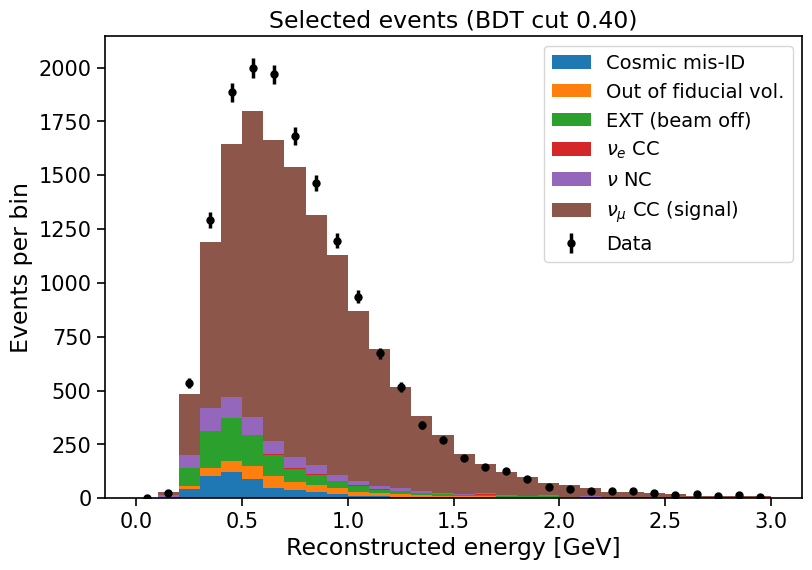

In [20]:
# Apply the same preselection and BDT cut to all three datasets. From here on:
#   sim_sel   selected simulation (no oscillation), with weights - the basis of every prediction
#   data_sel  selected real data, one row per real event - the observed spectrum for Task 6
#   osc_sel   selected oscillated simulation, with oscillated weights - the "observed" spectrum for Tasks 4-5

def kfold_score(df):
    """BDT score for events none of the 5 models trained on (real data). Each event is scored by ONE randomly
    chosen fold model, exactly as each simulated event is scored by one model (out-of-fold). Averaging all 5
    would smooth the scores, so the same cut would act slightly differently on data and simulation."""
    Xd = df[features].replace([np.inf, -np.inf], np.nan)
    scores = np.column_stack([m.predict_proba(Xd)[:, 1] for m in models])   # every model's score
    pick = np.random.default_rng(1).integers(0, len(models), len(df))       # one random model per event
    return scores[np.arange(len(df)), pick]

def select(df, cut):
    """Preselect a raw dataset, score it with the BDT, and keep events above the threshold."""
    df = preselect(df)   # same preselection as the simulation
    df["bdt"] = kfold_score(df)
    return df[df["bdt"] > cut]

sim_sel  = pre[pre["bdt_kfold"] > BEST_CUT]   # simulation already has out-of-fold scores
data_sel = select(data, BEST_CUT)

# The oscillated simulation holds exactly the same events as the simulation (only the weights differ).
# Every one of them was in the training set of 4 of the 5 models, so reuse their out-of-fold scores instead.
osc = preselect(load("OscillatedSimulation.pkl"))
assert (osc["event_id"].values == pre["event_id"].values).all()   # same events, same order
osc["bdt"] = pre["bdt_kfold"].values
osc_sel = osc[osc["bdt"] > BEST_CUT]

print("Selected simulation (weighted):", sim_sel[WGT].sum())
print("Selected data events:          ", len(data_sel))
print("Selected oscillated (weighted):", osc_sel[WGT].sum())

# Selected simulation stacked by true category, with real data on top
order = [4, 5, 7, 10, 31, 21]
labels = {21: r"$\nu_\mu$ CC (signal)", 31: r"$\nu$ NC", 10: r"$\nu_e$ CC",
          7: "EXT (beam off)", 5: "Out of fiducial vol.", 4: "Cosmic mis-ID"}
parts = [sim_sel[sim_sel[CAT] == c] for c in order]

plt.figure(figsize=(9, 6))
plt.hist([p[ENERGY] for p in parts], bins=ebins, weights=[p[WGT] for p in parts],
         stacked=True, label=[labels[c] for c in order])
counts, _ = np.histogram(data_sel[ENERGY], bins=ebins)
plt.errorbar(ecentres, counts, yerr=np.sqrt(counts), fmt="ko", markersize=5, label="Data")
plt.xlabel("Reconstructed energy [GeV]")
plt.ylabel("Events per bin")
plt.title(f"Selected events (BDT cut {BEST_CUT:.2f})")
plt.legend()
plt.show()

17. Data vs simulation: BDT score distribution (does the BDT behave the same on real data as on simulation?)

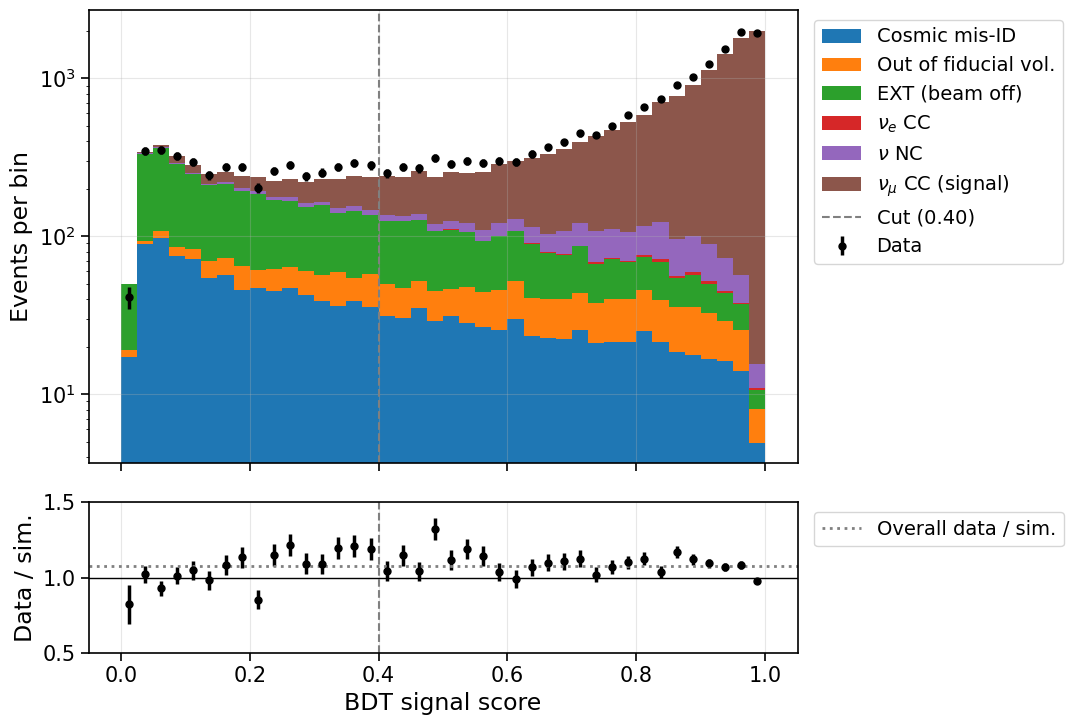

Data / simulation, all preselected events: 1.077
Data / simulation, after the cut:          1.079
Fraction passing the cut: data 0.787, simulation 0.785


In [21]:
# Does the BDT behave the same on real data as on simulation? Compare BDT score distributions of all
# preselected events (before the cut): simulation stacked by category (out-of-fold scores) vs real data.
# A flat data/simulation ratio means the cut keeps the same fraction of data as of simulation.
data_pre = preselect(data)              # all preselected real events
data_pre["bdt"] = kfold_score(data_pre)

sbins = np.linspace(0, 1, 41)
scentres = (sbins[:-1] + sbins[1:]) / 2
sim_parts = [pre[pre[CAT] == c] for c in order]
sim_total, _ = np.histogram(pre["bdt_kfold"], bins=sbins, weights=pre[WGT])
data_counts, _ = np.histogram(data_pre["bdt"], bins=sbins)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(11, 7.5), gridspec_kw={"height_ratios": [3, 1]})

ax1.hist([p["bdt_kfold"] for p in sim_parts], bins=sbins, weights=[p[WGT] for p in sim_parts],
         stacked=True, label=[labels[c] for c in order])
ax1.errorbar(scentres, data_counts, yerr=np.sqrt(data_counts), fmt="ko", markersize=5, label="Data")
ax1.set_yscale("log")
ax1.set_ylabel("Events per bin")

ratio = np.divide(data_counts, sim_total, out=np.full_like(sim_total, np.nan), where=sim_total > 0)
ratio_err = np.divide(np.sqrt(data_counts), sim_total, out=np.full_like(sim_total, np.nan), where=sim_total > 0)
ax2.errorbar(scentres, ratio, yerr=ratio_err, fmt="ko", markersize=5)
ax2.axhline(1, color="black", lw=1)
ax2.axhline(data_counts.sum() / sim_total.sum(), color="grey", ls=":", lw=2, label="Overall data / sim.")
ax2.set_ylim(0.5, 1.5)
ax2.set_ylabel("Data / sim.")
ax2.set_xlabel("BDT signal score")

for ax in (ax1, ax2):
    ax.axvline(BEST_CUT, color="grey", ls="--", lw=1.5, label=f"Cut ({BEST_CUT:.2f})" if ax is ax1 else None)
    ax.grid(alpha=0.3)
# Legends outside the plot, so they cover no data
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

passed = data_pre["bdt"] > BEST_CUT
print(f"Data / simulation, all preselected events: {len(data_pre) / pre[WGT].sum():.3f}")
print(f"Data / simulation, after the cut:          {passed.sum() / sim_sel[WGT].sum():.3f}")
print(f"Fraction passing the cut: data {passed.mean():.3f}, "
      f"simulation {sim_sel[WGT].sum() / pre[WGT].sum():.3f}")

Task 3: Predicting the selected energy spectrum for any oscillation parameters

Each selected simulated event is reweighted by its survival probability P(νμ→νμ), computed from its **true** neutrino energy, and then histogrammed in **reconstructed** energy. Because every event carries both, the prediction automatically includes energy smearing, selection efficiency and backgrounds. EXT (beam-off) events contain no neutrino, so they are not reweighted.

All beam-neutrino events are oscillated, not just νμ CC. That matches how OscillatedSimulation.pkl was made (see the answer-key check below) and is physically right for NC events in a 3+1 model, where νμ → ν_s also removes NC interactions. νe CC events would strictly follow their own survival probability, but they are only about 0.2% of the selection.

In [22]:
# Task 3 machinery. Input: the selected simulation sim_sel (no oscillation). For any (Δm², sin²2θ),
# predict() multiplies each event's weight by its survival probability (from its TRUE energy) and
# histograms its RECONSTRUCTED energy - the expected spectrum if those were the true parameters.
L_KM = 0.47                          # baseline: Fermilab target to MicroBooNE, in km (lab script)
TRUE_E = "Simulated neutrino energy" # true neutrino energy (simulation only), in GeV
MIN_EVENTS = 20                      # minimum expected events per bin with no oscillation, so the χ² behaves

def survival_prob(E_true, dm2, sin2_2theta, L=L_KM):
    """Two-flavour P(numu -> numu). E_true in GeV, L in km, dm2 in eV^2."""
    return 1 - sin2_2theta * np.sin(1.27 * dm2 * L / E_true) ** 2

def merge_bins(edges, counts, min_count):
    """Merge adjacent bins, from low to high energy, until each holds at least min_count."""
    new_edges, acc = [edges[0]], 0.0
    for c, right in zip(counts, edges[1:]):
        acc += c
        if acc >= min_count:
            new_edges.append(right)
            acc = 0.0
    if acc > 0:                      # leftover at the top joins the last bin
        new_edges[-1] = edges[-1]
    return np.array(new_edges)

# Reconstructed-energy binning: 0.1 GeV bins up to 3 GeV plus one overflow bin, merged where sparse.
# Chosen from the no-oscillation simulation only, never from the data.
fine_edges = np.r_[np.linspace(0, 3, 31), 100]
fine_counts, _ = np.histogram(sim_sel[ENERGY], bins=fine_edges, weights=sim_sel[WGT])
fit_edges = merge_bins(fine_edges, fine_counts, MIN_EVENTS)   # the bins used by every χ² from now on
n_bins = len(fit_edges) - 1

# Everything that doesn't change with the oscillation parameters is computed once
oscillates = (sim_sel[CAT] != 7).to_numpy()          # every beam-neutrino event; EXT (beam off) has no neutrino
E_true = sim_sel[TRUE_E].to_numpy()                   # sets each event's oscillation probability
w_nominal = sim_sel[WGT].to_numpy()                   # each event's weight with no oscillation
bin_idx = np.digitize(sim_sel[ENERGY], fit_edges) - 1   # which reconstructed-energy bin each event lands in

def predict(dm2, sin2_2theta):
    """Expected selected events per reconstructed-energy bin, and the variance from finite simulation statistics."""
    w = w_nominal * np.where(oscillates, survival_prob(E_true, dm2, sin2_2theta), 1.0)   # oscillated weights
    counts = np.bincount(bin_idx, weights=w, minlength=n_bins)        # sum of weights in each bin
    var_mc = np.bincount(bin_idx, weights=w ** 2, minlength=n_bins)   # sum of squared weights in each bin
    return counts, var_mc

def observed(df, weighted=True):
    """Histogram a selected sample in the fit binning (simulated samples use their weights; data counts 1 per event)."""
    counts, _ = np.histogram(df[ENERGY], bins=fit_edges, weights=df[WGT] if weighted else None)
    return counts

osc_obs = observed(osc_sel)                    # "observed" spectrum for Tasks 4-5
data_obs = observed(data_sel, weighted=False)  # observed spectrum for Task 6

# Checks
assert ((bin_idx >= 0) & (bin_idx < n_bins)).all(), "every selected event should land in a bin"
assert np.all(E_true[oscillates] > 0), "events with zero true energy would divide by zero"
assert np.allclose(predict(0, 0)[0], observed(sim_sel)), "no oscillation must reproduce the nominal spectrum"

print(f"{n_bins} bins, edges (GeV): {np.round(fit_edges, 2)}")
print("Expected events per bin with no oscillation:", np.round(predict(0, 0)[0]).astype(int))

27 bins, edges (GeV): [  0.    0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9   1.    1.1   1.2
   1.3   1.4   1.5   1.6   1.7   1.8   1.9   2.    2.1   2.2   2.3   2.4
   2.5   2.7   2.9 100. ]
Expected events per bin with no oscillation: [  28  485 1188 1648 1798 1664 1537 1316 1129  869  692  518  381  293
  206  160  124   97   72   60   46   31   29   23   31   21   43]


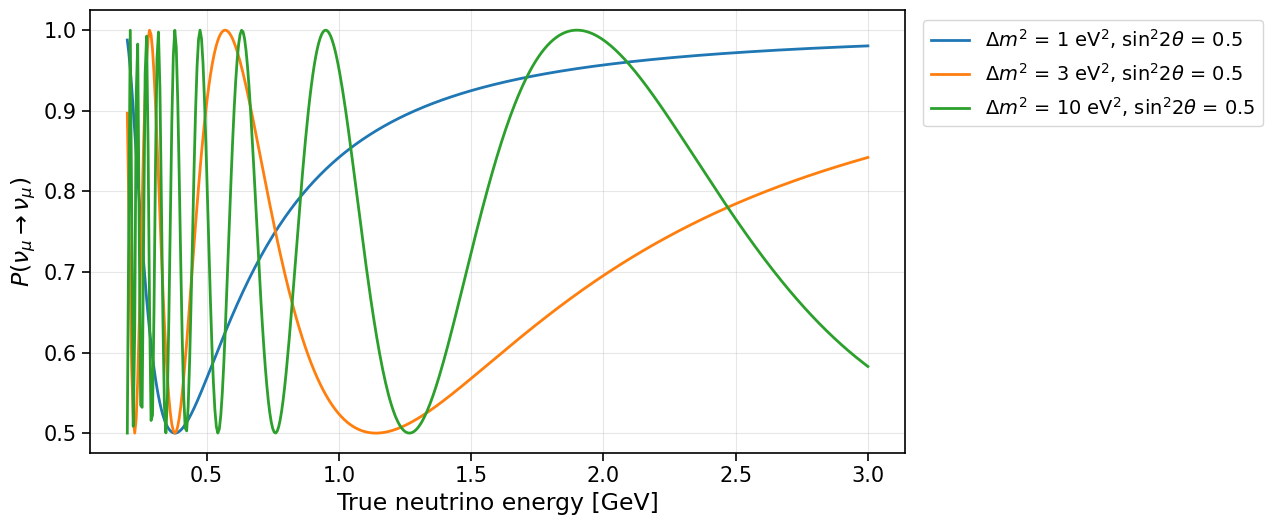

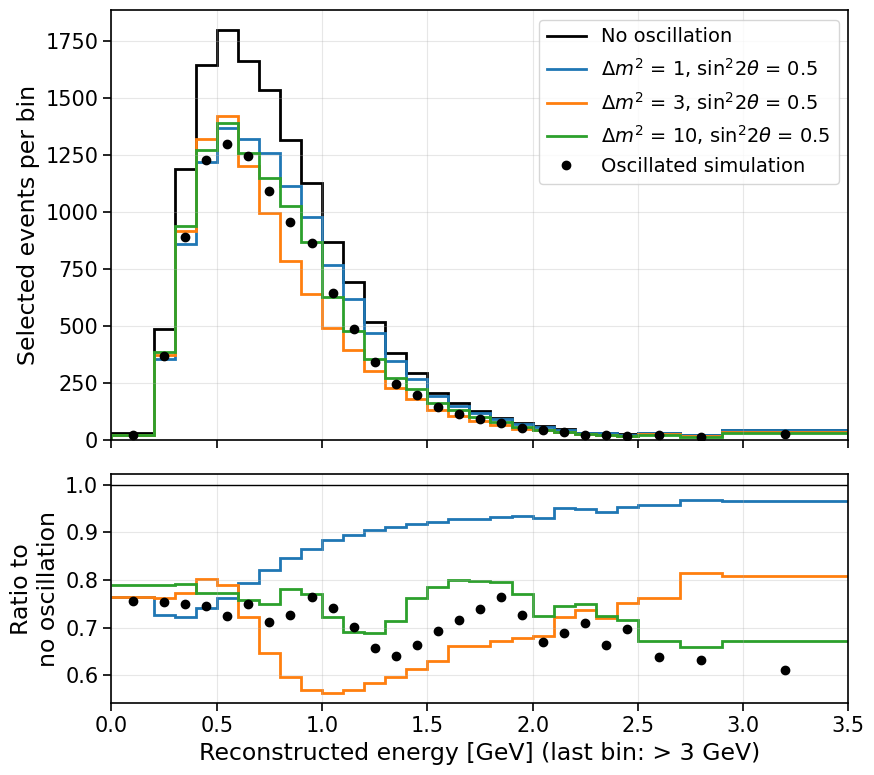

In [23]:
# Illustration of what predict() does, for three hand-picked parameter sets (not fitted):
# top = P(numu -> numu) against true energy; middle = predicted spectra; bottom = predictions divided by
# the no-oscillation spectrum. The oscillated simulation is shown as points for comparison.
examples = [(1, 0.5), (3, 0.5), (10, 0.5)]   # (dm2 [eV^2], sin^2 2theta) - illustrative, not fitted
nominal = predict(0, 0)[0]                    # expected spectrum with no oscillation
plot_edges = fit_edges.copy()
plot_edges[-1] = 3.5                          # draw the overflow bin (>= 3 GeV) as 3-3.5 GeV
plot_centres = (plot_edges[:-1] + plot_edges[1:]) / 2

# 1. Survival probability against true energy
E_grid = np.linspace(0.2, 3, 500)
fig, ax1 = plt.subplots(figsize=(13, 5.5))
for dm2, s in examples:
    ax1.plot(E_grid, survival_prob(E_grid, dm2, s), lw=2,
             label=fr"$\Delta m^2$ = {dm2} eV$^2$, sin$^2 2\theta$ = {s}")
ax1.set_xlabel("True neutrino energy [GeV]")
ax1.set_ylabel(r"$P(\nu_\mu \to \nu_\mu)$")
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Predicted selected spectra in reconstructed energy (top), and the same as a ratio to no oscillation:
#    the oscillation pattern after detector smearing (bottom)
fig, (ax2, ax3) = plt.subplots(2, 1, sharex=True, figsize=(9, 8), gridspec_kw={"height_ratios": [3, 1.6]})
ax2.stairs(nominal, plot_edges, color="black", lw=2, label="No oscillation")
for dm2, s in examples:
    ax2.stairs(predict(dm2, s)[0], plot_edges, lw=2, label=fr"$\Delta m^2$ = {dm2}, sin$^2 2\theta$ = {s}")
ax2.plot(plot_centres, osc_obs, "ko", markersize=6, label="Oscillated simulation")
ax2.set_ylabel("Selected events per bin")
ax2.legend()

for dm2, s in examples:
    ax3.stairs(predict(dm2, s)[0] / nominal, plot_edges, lw=2, baseline=None)
ax3.plot(plot_centres, osc_obs / nominal, "ko", markersize=6)
ax3.axhline(1, color="black", lw=1)
ax3.set_ylabel("Ratio to\nno oscillation")
ax3.set_xlabel("Reconstructed energy [GeV] (last bin: > 3 GeV)")
ax3.set_xlim(0, 3.5)
for ax in (ax2, ax3):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Task 4: χ² between an observed spectrum and the prediction

χ² = Σ (N_obs − N_pred)² / σ², with σ² per bin = Poisson (N_pred) + 15% systematic (uncorrelated between bins, from the lab script) + simulation statistics (Σw², left out for the oscillated set because it is built from the same simulated events as the prediction, so those fluctuations cancel)

In [24]:
# Task 4: one number for how well a prediction matches an observed spectrum (both in the fit binning).
SYST = 0.15   # fractional systematic per bin, uncorrelated between bins (lab script)

def chi2(obs, dm2, sin2_2theta, mc_stat=True, lam_sigma=None, return_lam=False, syst=None):
    """Pearson χ² between an observed spectrum and the prediction for (dm2, sin2_2theta).
    lam_sigma sets the overall normalisation λ of the prediction:
      None   -> λ fixed at 1 (default, as before)
      np.inf -> λ free (shape-only comparison)
      0.10   -> λ may move, with a Gaussian penalty ((λ - 1) / 0.10)²
    syst is the fractional per-bin systematic (None -> SYST, the lab script's 15%)"""
    syst = SYST if syst is None else syst
    pred, var_mc = predict(dm2, sin2_2theta)
    # Variance per bin: Poisson (= predicted count) + 15% systematic + simulation statistics (optional)
    var = pred + (syst * pred) ** 2 + (var_mc if mc_stat else 0)
    lam, penalty = 1.0, 0.0
    if lam_sigma is not None:
        # Best λ for this prediction (closed form, holding the variances fixed); 1/inf² = 0 when λ is free
        lam = (np.sum(obs * pred / var) + 1 / lam_sigma**2) / (np.sum(pred**2 / var) + 1 / lam_sigma**2)
        pred = lam * pred
        var = pred + (syst * pred) ** 2 + (lam**2 * var_mc if mc_stat else 0)
        penalty = ((lam - 1) / lam_sigma) ** 2
    value = np.sum((obs - pred) ** 2 / var) + penalty
    return (value, lam) if return_lam else value

# A few hand-picked parameter sets against the oscillated simulation: some should agree far better than others
# (mc_stat=False: the oscillated set is built from the same simulated events, so their fluctuations cancel)
test_points = [(0, 0), (1, 0.2), (1, 0.5), (3, 0.5), (10, 0.5), (30, 0.8)]
for dm2, s in test_points:
    print(f"Δm² = {dm2:>4} eV², sin²2θ = {s:.1f}:  χ² = {chi2(osc_obs, dm2, s, mc_stat=False):8.1f}"
          f"   ({n_bins} bins)")

Δm² =    0 eV², sin²2θ = 0.0:  χ² =     74.8   (27 bins)
Δm² =    1 eV², sin²2θ = 0.2:  χ² =     56.6   (27 bins)
Δm² =    1 eV², sin²2θ = 0.5:  χ² =     36.3   (27 bins)
Δm² =    3 eV², sin²2θ = 0.5:  χ² =     19.1   (27 bins)
Δm² =   10 eV², sin²2θ = 0.5:  χ² =      3.6   (27 bins)
Δm² =   30 eV², sin²2θ = 0.8:  χ² =     19.0   (27 bins)


Task 5: Grid search for the oscillation parameters of the oscillated simulation

Scan Δm² (log-spaced, 0.01–100 eV²) and sin²2θ (0–1), compute χ² at every point, and take the minimum as the best fit. Uncertainties come from Δχ² = χ² − χ²_min: for two parameters the 68% / 90% / 95% regions are Δχ² < 2.30 / 4.61 / 5.99; for one parameter (minimising over the other, "profiling") the 1σ range is Δχ² < 1.

The oscillated set has no random fluctuations (it is the simulation reweighted), so χ²_min should be close to zero and the contours show the analysis's expected sensitivity.

In [25]:
# Task 5: compute χ² against the oscillated simulation at every point of a (Δm², sin²2θ) grid
# and take the smallest as the best fit.
dm2_grid = np.logspace(-2, 2, 201)     # eV^2
s22t_grid = np.linspace(0, 1, 101)

def scan(obs, mc_stat, lam_sigma=None):
    """χ² at every grid point: rows are Δm², columns are sin²2θ (lam_sigma: see chi2)."""
    return np.array([[chi2(obs, dm2, s, mc_stat, lam_sigma) for s in s22t_grid] for dm2 in dm2_grid])

chi2_osc = scan(osc_obs, mc_stat=False)    # takes ~30 s
i, j = np.unravel_index(chi2_osc.argmin(), chi2_osc.shape)   # grid position of the minimum
best_dm2, best_s22t, chi2_min = dm2_grid[i], s22t_grid[j], chi2_osc[i, j]
dchi2 = chi2_osc - chi2_min                 # Δχ²: how much worse each point is than the best fit

# One-parameter uncertainties: minimise over the other parameter, then find where Δχ² < 1
prof_dm2 = dchi2.min(axis=1)
prof_s22t = dchi2.min(axis=0)

def one_sigma(grid, prof):
    """Smallest and largest grid values with Δχ² <= 1, and whether that range reaches the edge of the grid."""
    inside = grid[prof <= 1]
    at_edge = inside.min() == grid[0] or inside.max() == grid[-1]
    return inside.min(), inside.max(), at_edge

lo, hi, edge = one_sigma(dm2_grid, prof_dm2)
print(f"Best fit: Δm² = {best_dm2:.3g} eV², sin²2θ = {best_s22t:.2f}, χ²_min = {chi2_min:.2f} for {n_bins - 2} degrees of freedom")
print("  (near zero by construction: the oscillated set uses the same events as the prediction, so this is not a goodness-of-fit test)")
print(f"χ² with no oscillation: {chi2(osc_obs, 0, 0, mc_stat=False):.1f}")
print(f"Δm²   1σ range: {lo:.3g} – {hi:.3g} eV²" + ("  (reaches the edge of the grid)" if edge else ""))
lo, hi, edge = one_sigma(s22t_grid, prof_s22t)
print(f"sin²2θ 1σ range: {lo:.2f} – {hi:.2f}" + ("  (reaches the edge of the grid)" if edge else ""))

Best fit: Δm² = 11 eV², sin²2θ = 0.56, χ²_min = 0.07 for 25 degrees of freedom
  (near zero by construction: the oscillated set uses the same events as the prediction, so this is not a goodness-of-fit test)
χ² with no oscillation: 74.8
Δm²   1σ range: 10.5 – 12 eV²
sin²2θ 1σ range: 0.52 – 0.61


In [ ]:
# Slide figure style, shared by the closure and exclusion plots
COL_68, COL_90, COL_95 = "#08519c", "#4292c6", "#c6dbef"   # 68% dark, 90% mid, 95% light blue (same on every slide)
SLIDE_LABEL, SLIDE_TICK, SLIDE_LEGEND = 20, 16, 15          # font sizes that survive being pasted onto a slide

# Δχ² map with the 68% / 90% / 95% contours (two parameters)
# Points inside a contour are consistent with the oscillated simulation at that confidence level.
# The red cross is the value the oscillated set was made with (closure: the fit should land on it).
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from matplotlib.ticker import NullFormatter
CL_LEVELS = [2.30, 4.61, 5.99]            # Δχ² for 68% / 90% / 95% CL, two parameters
CL_COLOURS = ["white", "orange", "red"]
CL_NAMES = ["68% CL", "90% CL", "95% CL"]
OUTLINE = [pe.Stroke(linewidth=4.5, foreground="black"), pe.Normal()]   # visible on light and dark backgrounds

def draw_cl_contours(ax, grid):
    """68/90/95% contours of a Δχ² grid, outlined, with legend entries."""
    cs = ax.contour(s22t_grid, dm2_grid, grid, levels=CL_LEVELS, colors=CL_COLOURS, linewidths=2.5)
    cs.set_path_effects(OUTLINE)
    for col, name in zip(CL_COLOURS, CL_NAMES):
        ax.plot([], [], color=col, lw=2.5, path_effects=OUTLINE, label=name)   # legend entry

CLOSURE_TRUE = (0.556, 11.12)   # injected (sin²2θ, Δm²) of OscillatedSimulation.pkl
fig, ax = plt.subplots(figsize=(9, 7))
ax.contourf(s22t_grid, dm2_grid, dchi2, levels=[0, 2.30, 4.61, 5.99], colors=[COL_68, COL_90, COL_95])
ax.contour(s22t_grid, dm2_grid, dchi2, levels=CL_LEVELS, colors="black", linewidths=1)
ax.plot(best_s22t, best_dm2, "*", color="white", markersize=18, markeredgecolor="black", label="Best fit")
ax.plot(*CLOSURE_TRUE, "x", color="red", markersize=14, mew=3, label="True value")
handles = ax.get_legend_handles_labels()[0] + [Patch(facecolor=col, edgecolor="black", label=name)
                                               for col, name in zip([COL_68, COL_90, COL_95], CL_NAMES)]
ax.set_yscale("log")
ax.set_xlim(0.4, 0.8)    # zoomed to the contours (they span about 0.43-0.73)
ax.set_ylim(4, 100)      # the contours start near 8.5 eV²
ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8])
ax.set_yticks([5, 10, 20, 50, 100], ["5", "10", "20", "50", "100"])   # plain labels on the log axis
ax.minorticks_on()
ax.yaxis.set_minor_formatter(NullFormatter())   # minor ticks unlabelled, so they don't repeat the labels above
ax.grid(alpha=0.3)
ax.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$", fontsize=SLIDE_LABEL)
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]", fontsize=SLIDE_LABEL)
ax.tick_params(labelsize=SLIDE_TICK)
ax.legend(handles=handles, loc="lower center", ncol=3, fontsize=SLIDE_LEGEND)   # in the empty strip below the contours
plt.tight_layout()
fig.savefig("figures/closure_test_contours.png")
plt.show()

# One-parameter profiles: Δχ² minimised over the other parameter
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8))
ax1.plot(dm2_grid, prof_dm2, lw=2)
ax1.set_xscale("log")
ax1.set_xlabel(r"$\Delta m^2$ [eV$^2$]")
ax2.plot(s22t_grid, prof_s22t, lw=2)
ax2.set_xlabel(r"sin$^2 2\theta$")
for ax in (ax1, ax2):
    ax.axhline(1, color="grey", ls="--", lw=1, label=r"$\Delta\chi^2 = 1$ (1σ)")
    ax.axhline(2.71, color="grey", ls=":", lw=1, label=r"$\Delta\chi^2 = 2.71$ (90%)")
    ax.set_ylabel(r"$\Delta\chi^2$ (profiled)")
    ax.set_ylim(0, 20)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

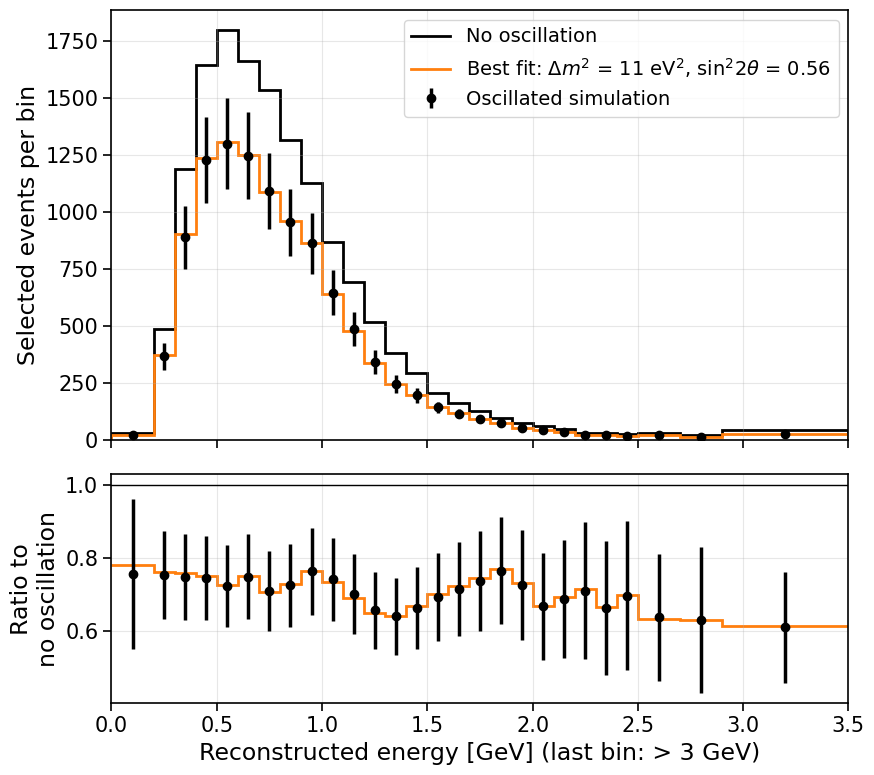

In [27]:
# Best-fit prediction against the oscillated simulation
best_pred = predict(best_dm2, best_s22t)[0]
err = np.sqrt(best_pred + (SYST * best_pred) ** 2)   # the uncertainty used in the χ²

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 8), gridspec_kw={"height_ratios": [3, 1.6]})
ax1.stairs(nominal, plot_edges, color="black", lw=2, label="No oscillation")
ax1.stairs(best_pred, plot_edges, color="C1", lw=2,
           label=fr"Best fit: $\Delta m^2$ = {best_dm2:.3g} eV$^2$, sin$^2 2\theta$ = {best_s22t:.2f}")
ax1.errorbar(plot_centres, osc_obs, yerr=err, fmt="ko", markersize=6, label="Oscillated simulation")
ax1.set_ylabel("Selected events per bin")
ax1.legend()

# Ratio to no oscillation shows the fitted disappearance pattern directly
ax2.stairs(best_pred / nominal, plot_edges, color="C1", lw=2, baseline=None)
ax2.errorbar(plot_centres, osc_obs / nominal, yerr=err / nominal, fmt="ko", markersize=6)
ax2.axhline(1, color="black", lw=1)
ax2.set_ylabel("Ratio to\nno oscillation")
ax2.set_xlabel("Reconstructed energy [GeV] (last bin: > 3 GeV)")
ax2.set_xlim(0, 3.5)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Validation: the oscillated set is the simulation reweighted, so for each event osc_weight / sim_weight is exactly the survival probability that was used to make it. Compare it with the fitted P(E) (only possible because this is simulation; real data has no such answer key)

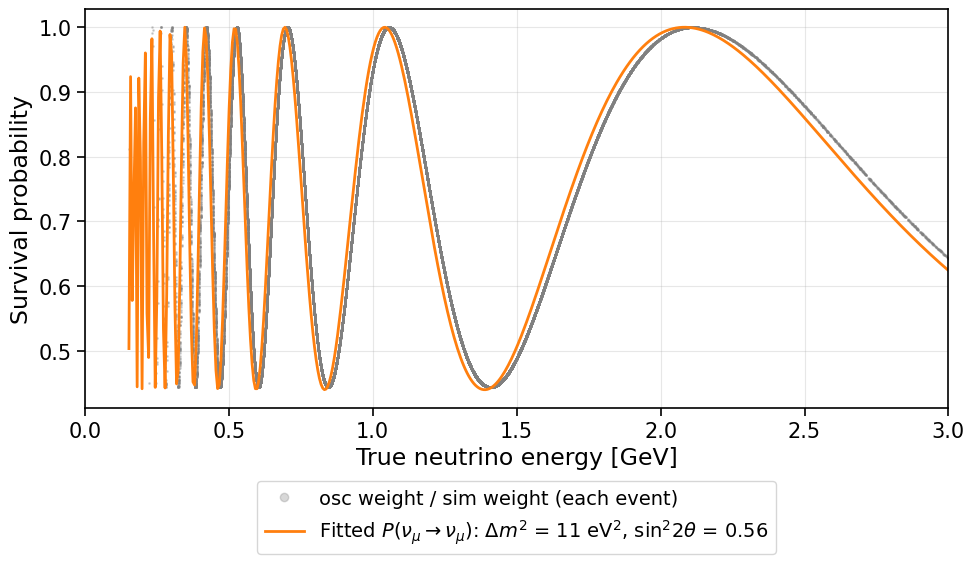

In [28]:
# Answer key: osc_sel and sim_sel are the same events, so dividing their weights gives, for each event,
# the survival probability used to build the oscillated set. Plot it against true energy with the fitted P(E).
nu = (osc_sel[CAT] != 7).to_numpy()                    # beam-neutrino events (EXT has no neutrino)
true_ratio = (osc_sel[WGT] / sim_sel[WGT]).to_numpy()[nu]
true_E = osc_sel[TRUE_E].to_numpy()[nu]

E_grid = np.linspace(true_E.min(), 3, 500)
plt.figure(figsize=(10, 6))
plt.plot(true_E, true_ratio, ".", color="grey", markersize=2, alpha=0.3, label="osc weight / sim weight (each event)")
plt.plot(E_grid, survival_prob(E_grid, best_dm2, best_s22t), color="C1", lw=2,
         label=fr"Fitted $P(\nu_\mu\to\nu_\mu)$: $\Delta m^2$ = {best_dm2:.3g} eV$^2$, sin$^2 2\theta$ = {best_s22t:.2f}")
plt.xlim(0, 3)
plt.xlabel("True neutrino energy [GeV]")
plt.ylabel("Survival probability")
plt.legend(markerscale=6, loc="upper center", bbox_to_anchor=(0.5, -0.16))   # below the plot
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Task 6: Oscillation parameters from the real MicroBooNE data

Same grid search, now against the selected data spectrum. The simulation-statistics term is included because the data is independent of the simulation. Real data has statistical fluctuations, so χ²_min should be roughly the number of degrees of freedom. Δχ² between no oscillation and the best fit says whether the data significantly prefers oscillation; if it doesn't, the Δχ² map is read as an exclusion region (Appendix D).

In [29]:
# Task 6: the same grid search, now against the REAL data spectrum (data_obs).
# mc_stat=True because the data is independent of the simulation used for the prediction.
from scipy.stats import chi2 as chi2_dist   # χ² probability distribution (renamed so it doesn't clash with our chi2 function)

chi2_data = scan(data_obs, mc_stat=True)    # takes ~30 s
i, j = np.unravel_index(chi2_data.argmin(), chi2_data.shape)
best_dm2_data, best_s22t_data, chi2_min_data = dm2_grid[i], s22t_grid[j], chi2_data[i, j]
dchi2_data = chi2_data - chi2_min_data
ndf = n_bins - 2                            # degrees of freedom: bins minus fitted parameters

# Compare with no oscillation: a large Δχ² would mean the data prefers oscillation
chi2_null = chi2(data_obs, 0, 0, mc_stat=True)
dchi2_null = chi2_null - chi2_min_data

print(f"Best fit: Δm² = {best_dm2_data:.3g} eV², sin²2θ = {best_s22t_data:.2f}")
print(f"χ²_min = {chi2_min_data:.1f} for {ndf} degrees of freedom "
      f"(goodness-of-fit p-value {chi2_dist.sf(chi2_min_data, ndf):.3f})")
# Approximate: at sin²2θ = 0 the value of Δm² has no effect, so Wilks' theorem only roughly applies
print(f"No oscillation: χ² = {chi2_null:.1f}, Δχ² = {dchi2_null:.1f} "
      f"(approximate p-value {chi2_dist.sf(dchi2_null, 2):.3g} for no oscillation, 2 parameters)")
print(f"Data / prediction with no oscillation (total): {data_obs.sum() / predict(0, 0)[0].sum():.3f}")

# 1σ ranges (only meaningful if the data prefers oscillation; otherwise they fill the grid)
prof_dm2_data = dchi2_data.min(axis=1)
prof_s22t_data = dchi2_data.min(axis=0)
lo, hi, edge = one_sigma(dm2_grid, prof_dm2_data)
print(f"Δm²   1σ range: {lo:.3g} – {hi:.3g} eV²" + ("  (reaches the edge of the grid)" if edge else ""))
lo, hi, edge = one_sigma(s22t_grid, prof_s22t_data)
print(f"sin²2θ 1σ range: {lo:.2f} – {hi:.2f}" + ("  (reaches the edge of the grid)" if edge else ""))

Best fit: Δm² = 0.01 eV², sin²2θ = 0.00
χ²_min = 15.8 for 25 degrees of freedom (goodness-of-fit p-value 0.921)
No oscillation: χ² = 15.8, Δχ² = 0.0 (approximate p-value 1 for no oscillation, 2 parameters)
Data / prediction with no oscillation (total): 1.079
Δm²   1σ range: 0.01 – 100 eV²  (reaches the edge of the grid)
sin²2θ 1σ range: 0.00 – 1.00  (reaches the edge of the grid)


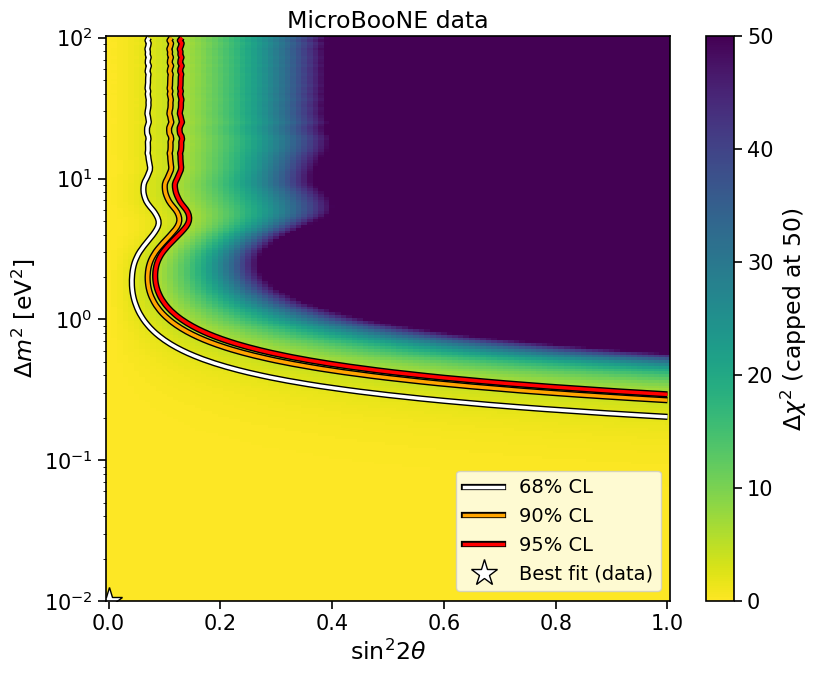

90% CL limit at Δm² = 0.302 eV²: sin²2θ < 0.788
90% CL limit at Δm² = 1 eV²: sin²2θ < 0.108
90% CL limit at Δm² = 3.02 eV²: sin²2θ < 0.084
90% CL limit at Δm² = 10 eV²: sin²2θ < 0.105


In [30]:
# Δχ² map for the data. If there is no significant preference for oscillation,
# the region outside the 90% contour is excluded at 90% confidence.
fig, ax = plt.subplots(figsize=(8.5, 7))
mesh = ax.pcolormesh(s22t_grid, dm2_grid, np.minimum(dchi2_data, 50), shading="auto", cmap="viridis_r")
fig.colorbar(mesh, ax=ax, label=r"$\Delta\chi^2$ (capped at 50)")
draw_cl_contours(ax, dchi2_data)   # defined with the Task 5 map
ax.plot(best_s22t_data, best_dm2_data, "w*", markersize=20, markeredgecolor="black", label="Best fit (data)")
ax.set_yscale("log")
ax.set_xlabel(r"sin$^2 2\theta$")
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax.set_title("MicroBooNE data")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 90% CL upper limits on sin²2θ: where the 90% contour crosses each Δm² row of the grid.
# (The one-parameter profiles are flat at zero for a null result, so they are replaced by these numbers.)
def limits_from_grid(dchi2_grid, level=4.61):
    """For each Δm² row: smallest sin²2θ with Δχ² >= level (linear interpolation). NaN if never reached
    (not excluded even at full mixing) or if sin²2θ = 0 is already above the level (no oscillation is itself
    outside the region, so the contour is an allowed island and there is no upper limit to quote)."""
    out = []
    for row in dchi2_grid:
        above = np.nonzero(row >= level)[0]
        if len(above) == 0 or above[0] == 0:
            out.append(np.nan)
        else:
            k = above[0]
            x0, x1, y0, y1 = s22t_grid[k - 1], s22t_grid[k], row[k - 1], row[k]
            out.append(x0 + (level - y0) * (x1 - x0) / (y1 - y0))
    return np.array(out)

REF_DM2_LIMITS = [0.3, 1, 3, 10]
ref_rows = [int(np.argmin(np.abs(np.log(dm2_grid / d)))) for d in REF_DM2_LIMITS]
lim_data = limits_from_grid(dchi2_data)
for d, k in zip(REF_DM2_LIMITS, ref_rows):
    print(f"90% CL limit at Δm² = {dm2_grid[k]:.3g} eV²: sin²2θ < {lim_data[k]:.3f}")


In [ ]:
# Exclusion plot for slides: the data map above on a log sin²2θ axis, with the 68% contour in blue so it stands out
# against the yellow, and the 90% CL limits from the cell above marked in orange.
# sin²2θ = 0 (no oscillation, which is also the best fit) cannot be shown on a log axis, so that column is left out.
LIMIT_COLOUR = "#e8590c"   # dark orange: readable on the yellow and different from the 90% line

def mark_limits(ax, limits, colour=LIMIT_COLOUR, label="90% CL limit"):
    """Orange points and values at the 90% CL limits (one per reference Δm²)."""
    pts = [(s, dm2_grid[k]) for s, k in zip(limits[ref_rows], ref_rows) if np.isfinite(s)]
    ax.plot(*zip(*pts), "o", color=colour, markersize=9, markeredgecolor="white", zorder=5, label=label)
    for s, d in pts:
        right = s < 0.4   # label to the right of the point unless it is near the edge of the plot
        ax.annotate(f"{s:.3f}", (s, d), xytext=(9 if right else -9, 5), textcoords="offset points",
                    ha="left" if right else "right", color=colour, fontsize=15, fontweight="bold", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))   # readable over the lines

fig, ax = plt.subplots(figsize=(8.5, 7))
mesh = ax.pcolormesh(s22t_grid[1:], dm2_grid, np.minimum(dchi2_data[:, 1:], 50), shading="auto", cmap="viridis_r")
fig.colorbar(mesh, ax=ax, label=r"$\Delta\chi^2$ (capped at 50)")
ax.contour(s22t_grid[1:], dm2_grid, dchi2_data[:, 1:], levels=CL_LEVELS, colors=["#3a7dff", "orange", "red"], linewidths=2)
for col, name in zip(["#3a7dff", "orange", "red"], CL_NAMES):
    ax.plot([], [], color=col, lw=2, label=name)   # legend entry
mark_limits(ax, lim_data)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 1)
ax.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$")
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax.legend(loc="lower left")
plt.tight_layout()
fig.savefig("figures/microboone_data_exclusion.png")
plt.show()


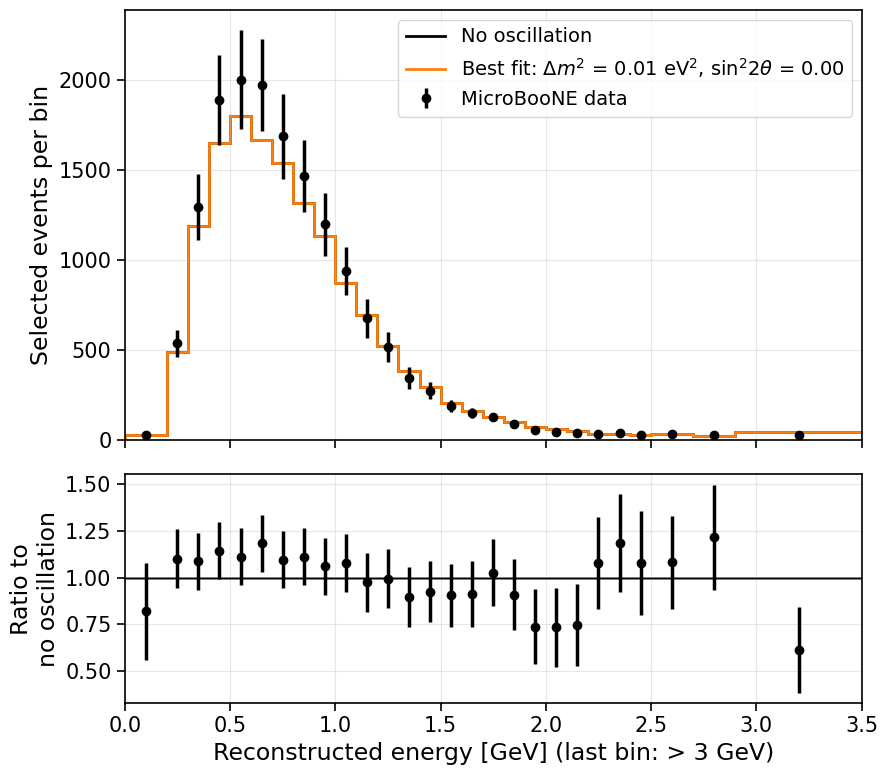

In [31]:
# Data against the no-oscillation and best-fit predictions
best_pred_data, best_var_mc = predict(best_dm2_data, best_s22t_data)
err = np.sqrt(best_pred_data + (SYST * best_pred_data) ** 2 + best_var_mc)   # the uncertainty used in the χ²

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 8), gridspec_kw={"height_ratios": [3, 1.6]})
ax1.stairs(nominal, plot_edges, color="black", lw=2, label="No oscillation")
ax1.stairs(best_pred_data, plot_edges, color="C1", lw=2,
           label=fr"Best fit: $\Delta m^2$ = {best_dm2_data:.3g} eV$^2$, sin$^2 2\theta$ = {best_s22t_data:.2f}")
ax1.errorbar(plot_centres, data_obs, yerr=err, fmt="ko", markersize=6, label="MicroBooNE data")
ax1.set_ylabel("Selected events per bin")
ax1.legend()

# Ratio to no oscillation: a real oscillation would show up as an energy-dependent dip below 1
ax2.stairs(best_pred_data / nominal, plot_edges, color="C1", lw=2, baseline=None)
ax2.errorbar(plot_centres, data_obs / nominal, yerr=err / nominal, fmt="ko", markersize=6)
ax2.axhline(1, color="black", lw=1)
ax2.set_ylabel("Ratio to\nno oscillation")
ax2.set_xlabel("Reconstructed energy [GeV] (last bin: > 3 GeV)")
ax2.set_xlim(0, 3.5)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Normalisation cross-check (λ) and expected sensitivity

The data has a few per cent more selected events than the no-oscillation prediction (the Task 6 cell prints the exact ratio). With the normalisation fixed
(as above), the fit counts that excess as evidence against any deficit, especially at large Δm², where an
oscillation is a flat deficit. Here an overall scale λ on the prediction is (a) free and (b) constrained to
±`LAMBDA_SIGMA`, and both are compared with the fixed fit and with the **expected** line (the no-oscillation
prediction used as data, i.e. what a world with no sterile neutrino would typically give).

- Fixed and free λ lines close together: the exclusion comes from the spectral **shape**.
- Free λ line much further right: the exclusion was driven by the overall **rate** (the data excess).
- Observed line further left than expected: the data fluctuated upwards, making deficits look less likely.
- λ-free contour closed (no oscillation outside it): with the rate free, the spectral shape alone prefers a
  dip. There is then no upper limit to quote. Check the λ–sin²2θ plot: a large best-fit λ with a dip means the
  fit is absorbing a tilt in the data (excess at low energy, deficit at high), which points to flux /
  cross-section / energy-scale mismodelling as much as to oscillation.

The free-λ fit uses one extra parameter, so its goodness of fit uses (bins − 3) degrees of freedom.

λ free: best fit Δm² = 4.57 eV², sin²2θ = 0.41, λ = 1.307, χ²_min = 10.0 for 24 degrees of freedom
λ free: Δχ² of no oscillation = 5.51
  -> no oscillation lies outside the λ-free 90% region, so that contour is a closed ALLOWED island,
     not an exclusion line, and its upper limits in the table are NaN (see the λ–sin²2θ plot below)

90% CL upper limits on sin²2θ (NaN = no upper limit, see limits_from_grid):
                 Observed, λ fixed  Observed, λ constrained (±10%)  Observed, λ free  Expected (no oscillation), λ fixed
Δm² = 0.302 eV²              0.788                           0.780               NaN                                 NaN
Δm² = 1 eV²                  0.108                           0.111               NaN                               0.215
Δm² = 3.02 eV²               0.084                           0.218               NaN                               0.103
Δm² = 10 eV²                 0.105                           0.274               NaN                   

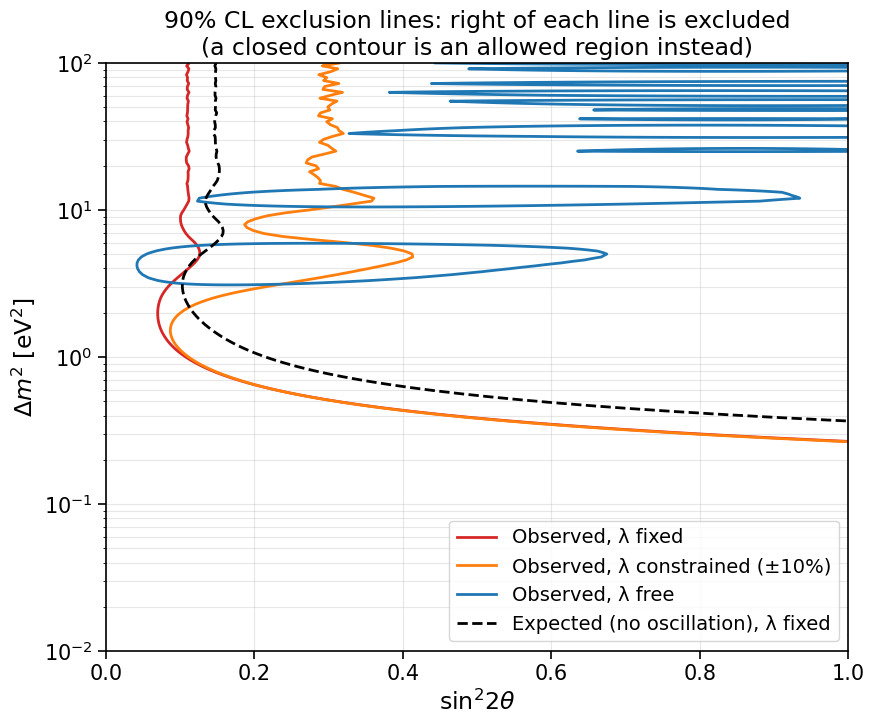

In [32]:
LAMBDA_SIGMA = 0.10   # assumed uncertainty on the overall normalisation for the constrained fit (discuss with a demonstrator)

def delta(grid):
    return grid - grid.min()

chi2_free = scan(data_obs, mc_stat=True, lam_sigma=np.inf)          # ~30 s each
chi2_con = scan(data_obs, mc_stat=True, lam_sigma=LAMBDA_SIGMA)
chi2_asimov = scan(predict(0, 0)[0], mc_stat=True)                   # expected: no-oscillation prediction as data

fits = {"Observed, λ fixed": dchi2_data,
        f"Observed, λ constrained (±{LAMBDA_SIGMA:.0%})": delta(chi2_con),
        "Observed, λ free": delta(chi2_free),
        "Expected (no oscillation), λ fixed": delta(chi2_asimov)}

# Best fit with λ free: where it is, the normalisation it wants, and whether the data prefers oscillation
i, j = np.unravel_index(chi2_free.argmin(), chi2_free.shape)
_, lam_best = chi2(data_obs, dm2_grid[i], s22t_grid[j], mc_stat=True, lam_sigma=np.inf, return_lam=True)
print(f"λ free: best fit Δm² = {dm2_grid[i]:.3g} eV², sin²2θ = {s22t_grid[j]:.2f}, λ = {lam_best:.3f}, "
      f"χ²_min = {chi2_free.min():.1f} for {n_bins - 3} degrees of freedom")
dchi2_null_free = chi2(data_obs, 0, 0, True, np.inf) - chi2_free.min()
print(f"λ free: Δχ² of no oscillation = {dchi2_null_free:.2f}")
if dchi2_null_free > 4.61:
    print("  -> no oscillation lies outside the λ-free 90% region, so that contour is a closed ALLOWED island,\n"
          "     not an exclusion line, and its upper limits in the table are NaN (see the λ–sin²2θ plot below)")
print()

# 90% CL limits at the reference Δm² values for each version
limit_table = pd.DataFrame({name: limits_from_grid(g)[ref_rows] for name, g in fits.items()},
                           index=[f"Δm² = {dm2_grid[k]:.3g} eV²" for k in ref_rows])
print("90% CL upper limits on sin²2θ (NaN = no upper limit, see limits_from_grid):")
print(limit_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 7.5))
styles = [("C3", "-"), ("C1", "-"), ("C0", "-"), ("k", "--")]
for (name, g), (col, ls) in zip(fits.items(), styles):
    ax.contour(s22t_grid, dm2_grid, g, levels=[4.61], colors=[col], linestyles=[ls], linewidths=2)
    ax.plot([], [], color=col, ls=ls, lw=2, label=name)     # legend entry for the contour
ax.set_yscale("log")
ax.set_xlabel(r"sin$^2 2\theta$")
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax.set_title("90% CL exclusion lines: right of each line is excluded\n"
             "(a closed contour is an allowed region instead)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

In [ ]:
# Observed vs expected 90% CL exclusion (λ fixed) on a log sin²2θ axis, with the observed limits marked (for slides,
# no title). Expected = the no-oscillation prediction used as data (chi2_asimov above). Right of the solid line is
# excluded. Dotted lines at 1, 3 and 10 eV² mark where the slide's table values are read off.
LIMIT_DARK = "#08306b"   # darker than COL_90 so the limit markers stand out from the observed line
d_exp = delta(chi2_asimov)
fig, ax = plt.subplots(figsize=(9, 7))
for d in (1, 3, 10):
    ax.axhline(d, color="grey", ls=":", lw=1, zorder=0)
ax.contourf(s22t_grid[1:], dm2_grid, dchi2_data[:, 1:], levels=[4.61, np.inf], colors=[COL_90], alpha=0.15)
ax.contour(s22t_grid[1:], dm2_grid, dchi2_data[:, 1:], levels=[4.61], colors=[COL_90], linewidths=3)
ax.contour(s22t_grid[1:], dm2_grid, d_exp[:, 1:], levels=[4.61], colors=["black"], linewidths=2.5, linestyles="--")
ax.plot([], [], color=COL_90, lw=3, label="Observed (90% CL)")   # legend entries for the contours
ax.plot([], [], color="black", lw=2.5, ls="--", label="Expected, no oscillation (90% CL)")
mark_limits(ax, lim_data, colour=LIMIT_DARK, label="90% CL limits")   # defined with the slide exclusion plot
ax.text(0.95, 40, "Excluded at 90% CL", color=LIMIT_DARK, fontsize=18, ha="right", va="center")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 1)     # two full decades, labelled at each decade
ax.set_xticks([0.01, 0.1, 1], [r"$10^{-2}$", r"$10^{-1}$", "1"])
ax.minorticks_on()
ax.set_yticks([0.1, 1, 10, 100], [r"$10^{-1}$", "1", "10", r"$10^{2}$"])
ax.xaxis.set_minor_formatter(NullFormatter())   # minor ticks unlabelled, so they don't repeat the labels above
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(0.1, 100)    # the lines end near 0.25 eV²; the space below holds the legend
ax.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$", fontsize=SLIDE_LABEL)
ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]", fontsize=SLIDE_LABEL)
ax.tick_params(labelsize=SLIDE_TICK)
ax.grid(alpha=0.3)
ax.grid(which="minor", axis="x", alpha=0.25)   # minor sin²2θ grid, for reading values off the log axis
ax.legend(loc="lower left", fontsize=SLIDE_LEGEND)
plt.tight_layout()
fig.savefig("figures/microboone_exclusion_obs_vs_exp.png")
plt.show()


In [ ]:
# λ–sin²2θ trade-off: how well every combination of normalisation λ and mixing sin²2θ fits the data,
# at two fixed Δm² values. λ is free here (no penalty), as in the "λ free" fit above.
# Shading is the relative likelihood exp(-Δχ²/2): 1 (darkest) at the best fit, falling off as the fit gets worse.
# The thick outer black line (0.1) is Δχ² = 4.61, i.e. the 90% CL region for two parameters.
# Slide fonts (SLIDE_LABEL etc.) as for the closure and exclusion plots.
lam_vals = np.linspace(0.8, 1.6, 161)
s_vals = np.linspace(0, 0.8, 81)

def chi2_lam_s(dm2):
    """χ² of data_obs at every (λ, sin²2θ) for one Δm²: same formula as chi2(), shape (len(lam_vals), len(s_vals))."""
    out = np.empty((len(lam_vals), len(s_vals)))
    for j, s in enumerate(s_vals):
        pred, var_mc = predict(dm2, s)
        p = lam_vals[:, None] * pred                                 # the prediction scaled by every λ at once
        var = p + (SYST * p) ** 2 + lam_vals[:, None] ** 2 * var_mc
        out[:, j] = np.sum((data_obs - p) ** 2 / var, axis=1)
    return out

panels = [(1.0, r"$\Delta m^2$ = 1 eV$^2$: dip"),
          (10.0, r"$\Delta m^2$ = 10 eV$^2$: flat deficit")]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True, constrained_layout=True)
for ax, (dm2, title) in zip(axes, panels):
    grid = chi2_lam_s(dm2)
    density = np.exp(-(grid - grid.min()) / 2)
    filled = ax.contourf(s_vals, lam_vals, density, levels=np.linspace(0, 1, 21), cmap="Blues")
    ax.contour(s_vals, lam_vals, density, levels=np.linspace(0.2, 0.9, 8), colors="black", linewidths=0.7)
    ax.contour(s_vals, lam_vals, density, levels=[0.1], colors="black", linewidths=2.2)   # exp(-Δχ²/2) = 0.1
    ax.axhline(1, color="C3", ls="--", lw=2, label=r"$\lambda$ = 1 (fixed)")
    ax.plot([], [], color="black", lw=2.2, label=r"90% CL ($\Delta\chi^2$ = 4.61)")   # legend entry for the thick line
    i, j = np.unravel_index(grid.argmin(), grid.shape)
    print(f"Δm² = {dm2:g} eV²: best fit λ = {lam_vals[i]:.3f}, sin²2θ = {s_vals[j]:.2f}, χ² = {grid.min():.1f}")
    ax.set_title(title, fontsize=SLIDE_LABEL)
    ax.set_xlabel(r"sin$^2 2\theta_{\mu\mu}$", fontsize=SLIDE_LABEL)
    ax.tick_params(labelsize=SLIDE_TICK)
    ax.legend(loc="lower right", fontsize=SLIDE_LEGEND)   # empty corner in both panels
axes[0].set_ylabel(r"Normalisation $\lambda$", fontsize=SLIDE_LABEL)
cbar = fig.colorbar(filled, ax=axes, ticks=np.arange(0, 1.01, 0.15))
cbar.set_label(r"Relative likelihood, $L/L_{\max} = \exp(-\Delta\chi^2/2)$", fontsize=SLIDE_LEGEND)
cbar.ax.tick_params(labelsize=SLIDE_TICK)
fig.savefig("figures/lambda_s22t_tradeoff.png")
plt.show()


Assumption test: size of the systematic uncertainty

The lab script gives a 15% per-bin systematic (uncorrelated between bins). Here the Task 6 fit and the expected
(Asimov) limit are repeated for several sizes at once, and the change in the 90% CL limits is recorded.

- **Table:** goodness of fit, Δχ² of no oscillation, and the observed / expected 90% limits on sin²2θ at the
  reference Δm² values, plus the shift of the 1 eV² limit relative to 15%.
- **Overlay:** the 90% CL exclusion line for each size (solid = observed, dashed = expected, same colour).
- **Calibration:** χ²_min / ndf against the systematic size. Each χ² term should average about 1, so the size
  where χ²_min ≈ ndf is the one the data's scatter supports. This assumes the model is otherwise right, and
  χ²_min itself fluctuates by about √(2 ndf), so it is a consistency check, not a measurement of the systematic.

The prediction is linear in sin²2θ (and Σw² quadratic), so the prediction at every grid point is computed once
and every systematic size reuses it: the whole comparison takes seconds instead of ~30 s per scan.

**Held fixed:** the BDT cut (`BEST_CUT`, chosen with a 15% systematic), so each shift shows only how the fit
treats the uncertainty. **To do later:** also re-choose the cut with each systematic size (`CUT_SYST` in 13b)
to see whether the optimal cut moves.

In [34]:
# Systematic-size test, part 1: the prediction at every (Δm², sin²2θ) grid point, computed once.
# For events that oscillate, the weight is w(1 - s·x) with s = sin²2θ and x = sin²(1.27 Δm² L / E); EXT has x = 0.
# So per Δm² row:  counts(s) = N0 - s·A   and   Σw²(s) = V0 - 2s·B + s²·C,
# with A = Σ w·x, B = Σ w²·x, C = Σ w²·x² per bin: four bincounts per row instead of one per grid point.
def predict_grid(dm2_values=dm2_grid, s_values=s22t_grid, L=L_KM):
    """predict() at every grid point: counts and Σw², each of shape (n_dm2, n_s, n_bins).
    L is the baseline in km: one number, or one value per selected simulated event."""
    N0 = np.bincount(bin_idx, weights=w_nominal, minlength=n_bins)
    V0 = np.bincount(bin_idx, weights=w_nominal ** 2, minlength=n_bins)
    s = np.asarray(s_values)[:, None]                      # (n_s, 1), broadcasts over bins
    counts = np.empty((len(dm2_values), len(s_values), n_bins))
    var_mc = np.empty_like(counts)
    for k, dm2 in enumerate(dm2_values):
        x = np.where(oscillates, np.sin(1.27 * dm2 * L / E_true) ** 2, 0.0)   # deficit at full mixing
        A = np.bincount(bin_idx, weights=w_nominal * x, minlength=n_bins)
        B = np.bincount(bin_idx, weights=w_nominal ** 2 * x, minlength=n_bins)
        C = np.bincount(bin_idx, weights=w_nominal ** 2 * x ** 2, minlength=n_bins)
        counts[k] = N0 - s * A
        var_mc[k] = V0 - 2 * s * B + s ** 2 * C
    return counts, var_mc

pred_grid, varmc_grid = predict_grid()

def chi2_grid(obs, syst=None, mc_stat=True, lam_sigma=None, grids=None):
    """chi2() at every grid point at once (same formula and λ options): shape (n_dm2, n_s).
    grids: (counts, Σw²) from predict_grid(); None -> the standard ones (fixed L = L_KM)."""
    syst = SYST if syst is None else syst
    pred, varmc = (pred_grid, varmc_grid) if grids is None else grids
    var = pred + (syst * pred) ** 2 + (varmc if mc_stat else 0)
    penalty = 0.0
    if lam_sigma is not None:
        lam = ((np.sum(obs * pred / var, axis=-1) + 1 / lam_sigma**2)
               / (np.sum(pred ** 2 / var, axis=-1) + 1 / lam_sigma**2))[..., None]
        pred = lam * pred
        var = pred + (syst * pred) ** 2 + (lam ** 2 * varmc if mc_stat else 0)
        penalty = ((lam[..., 0] - 1) / lam_sigma) ** 2
    return np.sum((obs - pred) ** 2 / var, axis=-1) + penalty

# Checks: the fast version must reproduce predict() and every grid scan already done above
k, j = 120, 37                                             # an arbitrary grid point
assert np.allclose(pred_grid[k, j], predict(dm2_grid[k], s22t_grid[j])[0])
assert np.allclose(varmc_grid[k, j], predict(dm2_grid[k], s22t_grid[j])[1])
assert np.allclose(chi2_grid(osc_obs, mc_stat=False), chi2_osc)                 # Task 5
assert np.allclose(chi2_grid(data_obs), chi2_data)                              # Task 6
assert np.allclose(chi2_grid(data_obs, lam_sigma=np.inf), chi2_free)            # λ free
assert np.allclose(chi2_grid(data_obs, lam_sigma=LAMBDA_SIGMA), chi2_con)       # λ constrained
print("Fast grid χ² matches predict() and the Task 5, Task 6 and λ scans")

Fast grid χ² matches predict() and the Task 5, Task 6 and λ scans


90% CL limits on sin²2θ (NaN = no upper limit, see limits_from_grid), observed and expected:
                    χ²_min  ndf  p-value  best Δm²  best sin²2θ  Δχ² no osc.  obs @ 0.3 eV²  exp @ 0.3 eV²  obs @ 1 eV²  exp @ 1 eV²  obs @ 3 eV²  exp @ 3 eV²  obs @ 10 eV²  exp @ 10 eV²  obs @ 1 eV² shift vs 15%
λ       systematic                                                                                                                                                                                                  
λ fixed 0.05        54.524   25    0.001     0.010         0.00        0.000          0.144          0.666        0.019        0.093        0.017        0.049         0.020         0.067                    -0.089
        0.10        25.716   25    0.423     0.010         0.00        0.000          0.421            NaN        0.057        0.155        0.050        0.076         0.061         0.104                    -0.051
        0.15        15.787   25    0.921     0.010     

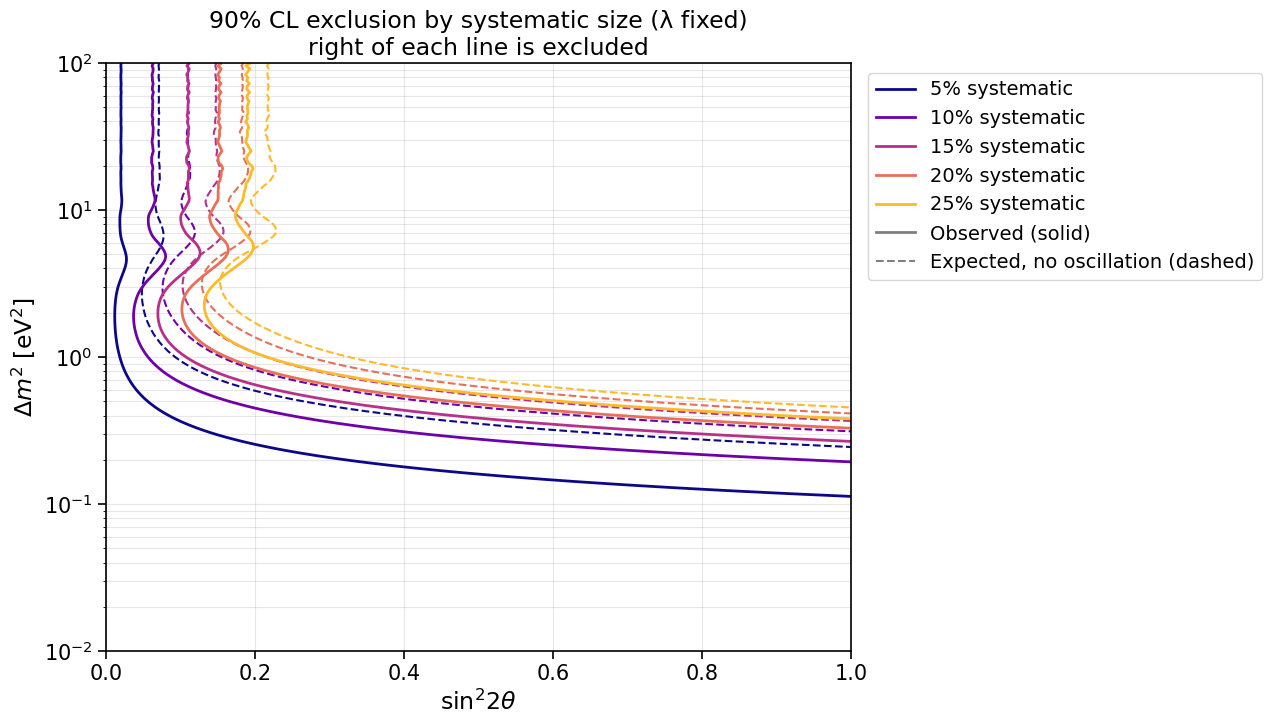

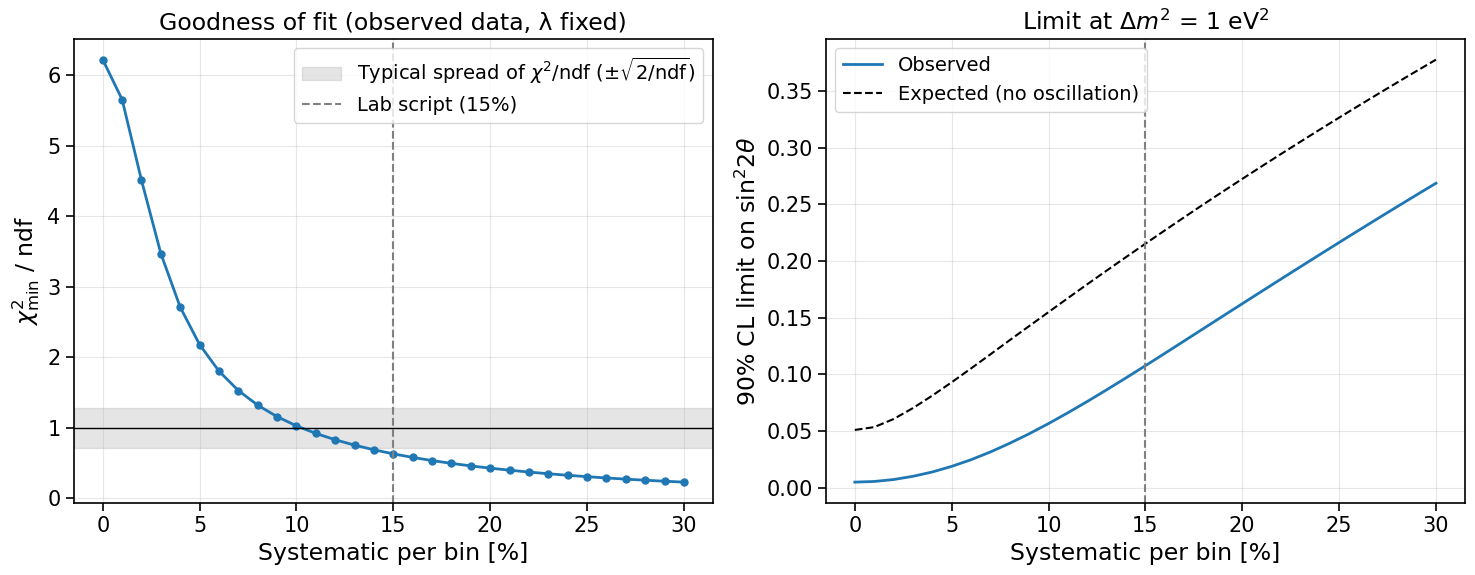

χ²_min = ndf (25) at a systematic of about 10.3% per bin


In [35]:
# Systematic-size test, part 2: the Task 6 fit and the expected (Asimov) limit for several systematic sizes.
SYST_VALUES = [0.05, 0.10, 0.15, 0.20, 0.25]   # 15% = lab script; 5% = ref [1]'s hypothetical near-detector case
INCLUDE_LAMBDA_FREE = False                     # True: repeat everything with λ free (shape-only fit) as well
asimov_obs = predict(0, 0)[0]                   # expected: the no-oscillation prediction used as data
k1 = ref_rows[REF_DM2_LIMITS.index(1)]          # grid row closest to Δm² = 1 eV² (the headline limit)

modes = {"λ fixed": None}
if INCLUDE_LAMBDA_FREE:
    modes["λ free"] = np.inf

rows, contours = [], {}
for mode, lam_sigma in modes.items():
    ndf_mode = n_bins - (2 if lam_sigma is None else 3)    # bins minus fitted parameters (Δm², sin²2θ, λ)
    for syst in SYST_VALUES:
        obs_grid = chi2_grid(data_obs, syst, lam_sigma=lam_sigma)
        exp_grid = chi2_grid(asimov_obs, syst, lam_sigma=lam_sigma)
        d_obs, d_exp = obs_grid - obs_grid.min(), exp_grid - exp_grid.min()
        contours[mode, syst] = d_obs, d_exp
        lim_obs, lim_exp = limits_from_grid(d_obs), limits_from_grid(d_exp)
        i, j = np.unravel_index(obs_grid.argmin(), obs_grid.shape)
        row = {"λ": mode, "systematic": syst,
               "χ²_min": obs_grid.min(), "ndf": ndf_mode, "p-value": chi2_dist.sf(obs_grid.min(), ndf_mode),
               "best Δm²": dm2_grid[i], "best sin²2θ": s22t_grid[j],
               "Δχ² no osc.": d_obs[0, 0]}      # sin²2θ = 0 column: no oscillation (the same for every Δm²)
        for d, k in zip(REF_DM2_LIMITS, ref_rows):
            row[f"obs @ {d:g} eV²"] = lim_obs[k]
            row[f"exp @ {d:g} eV²"] = lim_exp[k]
        rows.append(row)

syst_table = pd.DataFrame(rows).set_index(["λ", "systematic"])
if 0.15 in SYST_VALUES:   # shift of the headline number relative to the lab script's 15%
    ref15 = syst_table["obs @ 1 eV²"].groupby(level="λ").transform(lambda s: s.xs(0.15, level="systematic").iloc[0])
    syst_table["obs @ 1 eV² shift vs 15%"] = syst_table["obs @ 1 eV²"] - ref15
with pd.option_context("display.width", 250, "display.max_columns", 30):
    print("90% CL limits on sin²2θ (NaN = no upper limit, see limits_from_grid), observed and expected:")
    print(syst_table.round(3).to_string())

# Overlay of the 90% CL exclusion lines: one colour per systematic size, solid = observed, dashed = expected
colours = plt.cm.plasma(np.linspace(0, 0.85, len(SYST_VALUES)))
fig, axes = plt.subplots(1, len(modes), figsize=(9 * len(modes) + 4, 7.5), squeeze=False)
for ax, mode in zip(axes[0], modes):
    for syst, col in zip(SYST_VALUES, colours):
        d_obs, d_exp = contours[mode, syst]
        ax.contour(s22t_grid, dm2_grid, d_obs, levels=[4.61], colors=[col], linewidths=2)
        ax.contour(s22t_grid, dm2_grid, d_exp, levels=[4.61], colors=[col], linewidths=1.5, linestyles="--")
        ax.plot([], [], color=col, lw=2, label=f"{syst:.0%} systematic")    # legend entry for the contours
    ax.plot([], [], color="grey", lw=2, label="Observed (solid)")
    ax.plot([], [], color="grey", lw=1.5, ls="--", label="Expected, no oscillation (dashed)")
    ax.set_yscale("log")
    ax.set_xlabel(r"sin$^2 2\theta$")
    ax.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
    ax.set_title(f"90% CL exclusion by systematic size ({mode})\nright of each line is excluded")
    ax.grid(alpha=0.3, which="both")
axes[0, -1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))   # one legend, outside the plot
plt.tight_layout()
plt.show()

# Calibration: which systematic size does the data's bin-to-bin scatter support? (λ fixed)
syst_fine = np.linspace(0, 0.30, 31)
chi2min_fine = np.array([chi2_grid(data_obs, s).min() for s in syst_fine])
lim1_obs = np.array([limits_from_grid(chi2_grid(data_obs, s) - chi2_grid(data_obs, s).min())[k1] for s in syst_fine])
lim1_exp = np.array([limits_from_grid(chi2_grid(asimov_obs, s) - chi2_grid(asimov_obs, s).min())[k1] for s in syst_fine])
ndf_fixed = n_bins - 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.plot(syst_fine * 100, chi2min_fine / ndf_fixed, "o-", lw=2, markersize=5)
ax1.axhline(1, color="black", lw=1)
ax1.axhspan(1 - np.sqrt(2 / ndf_fixed), 1 + np.sqrt(2 / ndf_fixed), color="grey", alpha=0.2,
            label=r"Typical spread of $\chi^2$/ndf ($\pm\sqrt{2/\mathrm{ndf}}$)")
ax1.axvline(15, color="grey", ls="--", lw=1.5, label="Lab script (15%)")
ax1.set_xlabel("Systematic per bin [%]")
ax1.set_ylabel(r"$\chi^2_{\min}$ / ndf")
ax1.set_title("Goodness of fit (observed data, λ fixed)")
ax1.legend()
ax2.plot(syst_fine * 100, lim1_obs, lw=2, label="Observed")
ax2.plot(syst_fine * 100, lim1_exp, "k--", lw=1.5, label="Expected (no oscillation)")
ax2.axvline(15, color="grey", ls="--", lw=1.5)
ax2.set_xlabel("Systematic per bin [%]")
ax2.set_ylabel(r"90% CL limit on sin$^2 2\theta$")
ax2.set_title(fr"Limit at $\Delta m^2$ = {dm2_grid[k1]:.3g} eV$^2$")
ax2.legend()
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Systematic size at which χ²_min = ndf (χ²_min falls as the systematic grows)
if chi2min_fine[0] > ndf_fixed > chi2min_fine[-1]:
    s_match = np.interp(ndf_fixed, chi2min_fine[::-1], syst_fine[::-1])
    print(f"χ²_min = ndf ({ndf_fixed}) at a systematic of about {s_match:.1%} per bin")
elif chi2min_fine[0] <= ndf_fixed:
    print(f"χ²_min ≤ ndf ({ndf_fixed}) even with no systematic ({chi2min_fine[0]:.1f}): "
          "statistics (and simulation statistics) alone already cover the data's scatter")
else:
    print(f"χ²_min > ndf even at {syst_fine[-1]:.0%}: the scatter needs a larger systematic, or the model is off")

Assumption test: fixed baseline (470 m) vs each event's true flight distance

The survival probability depends on each neutrino's own L/E. The lab script uses a fixed L = 470 m, but the
simulation records every neutrino's true flight distance (`Simulated neutrino flight distance`, in metres).
Neutrinos are born wherever the parent meson decays along the ~50 m decay pipe, so the true L is spread over
~420–467 m (5–95%) with a median of ~447 m: 470 m is close to the **maximum**, not the typical value. A fixed 470 m
therefore overestimates the oscillation phase 1.27 Δm² L / E by ~5% for a typical event. The phase depends only
on the product Δm²·L, so this moves the predicted dip by ~5% in Δm² (a bias, which the per-bin 15% systematic
does not cover); the ±3% spread in L also smears the dip slightly.

Only the **prediction** changes: the data are only counted, so they never need an L (just as they never need a
true energy). The extra assumption is that the beam simulation models where the mesons decay.

- **Table:** goodness of fit, Δχ² of no oscillation, and the observed / expected 90% limits on sin²2θ for both
  choices, plus the closure-test best fit with each L.
- **Closure:** OscillatedSimulation.pkl was generated with exactly L = 470 m (its weight ratios fit
  1 − 0.556 sin²(1.27 × 11.12 eV² × 0.47 km / E) to machine precision; per-event L does not fit them), so Task 5
  keeps the fixed L. With per-event L the closure fit should move to slightly higher Δm² (~11.12 × 470/447):
  that shows the size of the effect, not a failure of the method. The Δm² grid steps are ~4.7%, about the size
  of the shift, so read the shift from the limits and the overlay rather than from the best-fit grid point.
- **Overlay:** 90% CL lines for both choices (solid = observed, dashed = expected), and the ratio of the limits.

**Held fixed:** the BDT cut and the binning (chosen with 470 m), the 15% systematic, λ fixed at 1.

True flight distance, selected beam-neutrino events: median 448 m, weighted mean 446 m, 5-95% 421-466 m (fixed value 470 m)



90% CL limits on sin²2θ (NaN = no upper limit, see limits_from_grid), observed and expected:
                      χ²_min  p-value  best Δm²  best sin²2θ  Δχ² no osc.  closure Δm²  closure sin²2θ  obs @ 0.3 eV²  exp @ 0.3 eV²  obs @ 1 eV²  exp @ 1 eV²  obs @ 3 eV²  exp @ 3 eV²  obs @ 10 eV²  exp @ 10 eV²
L                                                                                                                                                                                                                   
fixed 0.47 km         15.787    0.921      0.01          0.0          0.0       10.965            0.56          0.788            NaN        0.108        0.215        0.084        0.103         0.105         0.138
true flight distance  15.787    0.921      0.01          0.0          0.0       12.023            0.56          0.855            NaN        0.114        0.228        0.081        0.104         0.103         0.143

(closure: OscillatedSimulation.pkl was made with L = 4

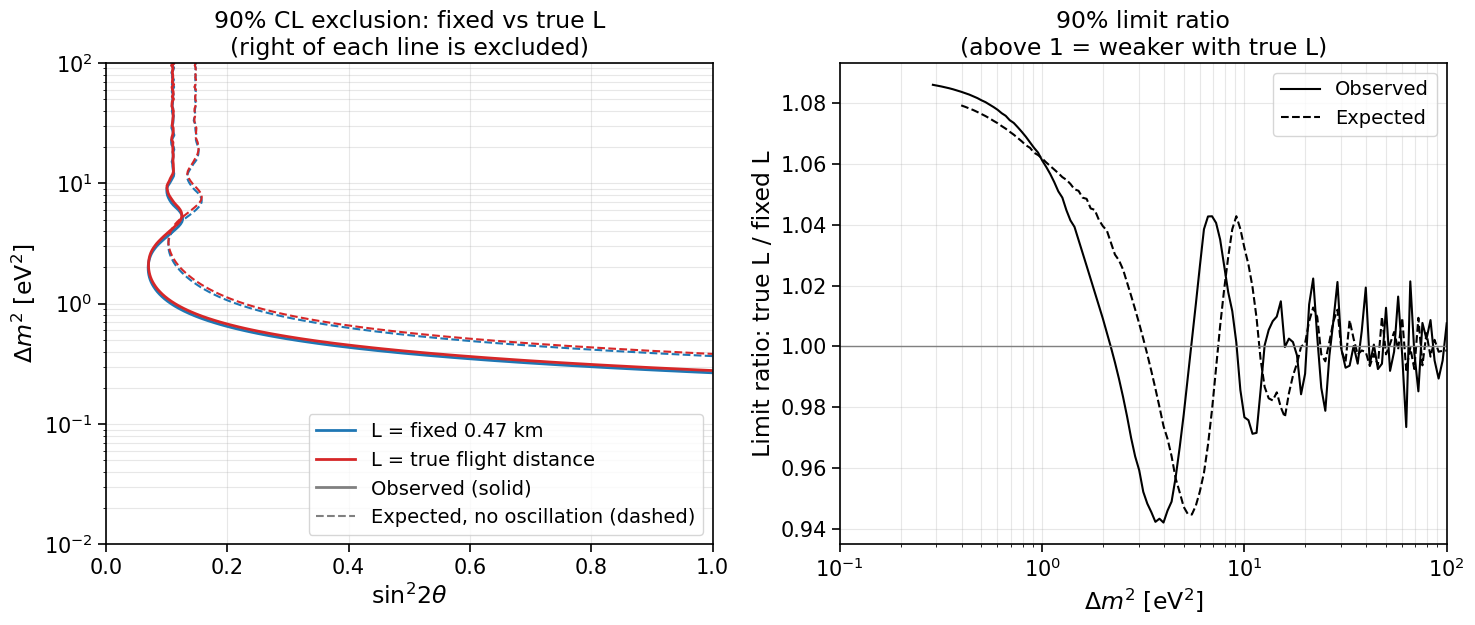

observed 90% limit at Δm² = 1 eV²: 0.108 (fixed L) -> 0.114 (true L), +6.1%
expected 90% limit at Δm² = 1 eV²: 0.215 (fixed L) -> 0.228 (true L), +6.2%


In [36]:
# Flight-distance test: the Task 6 fit, the expected (Asimov) limit and the closure fit, with each simulated event's
# TRUE flight distance as L instead of the fixed 0.47 km. Only the prediction changes; the data are just counted.
FLIGHT = "Simulated neutrino flight distance"   # truth column, in metres (0 for EXT, which doesn't oscillate)
L_true = sim_sel[FLIGHT].to_numpy() / 1000      # km, one value per selected simulated event
L_nu = L_true[oscillates]
assert np.all((L_nu > 0.3) & (L_nu < 0.5)), "flight distances should be ~0.41-0.47 km (column in metres)"
print(f"True flight distance, selected beam-neutrino events: median {np.median(L_nu) * 1000:.0f} m, "
      f"weighted mean {np.average(L_nu, weights=w_nominal[oscillates]) * 1000:.0f} m, "
      f"5-95% {np.percentile(L_nu, 5) * 1000:.0f}-{np.percentile(L_nu, 95) * 1000:.0f} m (fixed value {L_KM * 1000:.0f} m)\n")

L_choices = {"fixed 0.47 km": (pred_grid, varmc_grid),
             "true flight distance": predict_grid(L=L_true)}
# asimov_obs (the no-oscillation prediction) is the same for both: with no oscillation L plays no part

rows, contours_L, limits_L = [], {}, {}
for name, grids in L_choices.items():
    obs_grid = chi2_grid(data_obs, grids=grids)
    exp_grid = chi2_grid(asimov_obs, grids=grids)
    osc_grid = chi2_grid(osc_obs, mc_stat=False, grids=grids)      # closure test (Task 5) with this L
    d_obs, d_exp = obs_grid - obs_grid.min(), exp_grid - exp_grid.min()
    contours_L[name] = d_obs, d_exp
    limits_L[name] = limits_from_grid(d_obs), limits_from_grid(d_exp)
    i, j = np.unravel_index(obs_grid.argmin(), obs_grid.shape)
    io, jo = np.unravel_index(osc_grid.argmin(), osc_grid.shape)
    row = {"L": name, "χ²_min": obs_grid.min(), "p-value": chi2_dist.sf(obs_grid.min(), n_bins - 2),
           "best Δm²": dm2_grid[i], "best sin²2θ": s22t_grid[j], "Δχ² no osc.": d_obs[0, 0],
           "closure Δm²": dm2_grid[io], "closure sin²2θ": s22t_grid[jo]}
    for d, k in zip(REF_DM2_LIMITS, ref_rows):
        row[f"obs @ {d:g} eV²"] = limits_L[name][0][k]
        row[f"exp @ {d:g} eV²"] = limits_L[name][1][k]
    rows.append(row)

L_table = pd.DataFrame(rows).set_index("L")
with pd.option_context("display.width", 250, "display.max_columns", 30):
    print("90% CL limits on sin²2θ (NaN = no upper limit, see limits_from_grid), observed and expected:")
    print(L_table.round(3).to_string())
print("\n(closure: OscillatedSimulation.pkl was made with L = 470 m and Δm² = 11.12 eV², sin²2θ = 0.556)")

# Left: the 90% CL lines. Right: ratio of the limits (true L / fixed L) at each Δm²
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5))
for (name, (d_obs, d_exp)), col in zip(contours_L.items(), ["C0", "C3"]):
    ax1.contour(s22t_grid, dm2_grid, d_obs, levels=[4.61], colors=[col], linewidths=2)
    ax1.contour(s22t_grid, dm2_grid, d_exp, levels=[4.61], colors=[col], linewidths=1.5, linestyles="--")
    ax1.plot([], [], color=col, lw=2, label=f"L = {name}")
ax1.plot([], [], color="grey", lw=2, label="Observed (solid)")
ax1.plot([], [], color="grey", lw=1.5, ls="--", label="Expected, no oscillation (dashed)")
ax1.set_yscale("log")
ax1.set_xlabel(r"sin$^2 2\theta$")
ax1.set_ylabel(r"$\Delta m^2$ [eV$^2$]")
ax1.set_title("90% CL exclusion: fixed vs true L\n(right of each line is excluded)")
ax1.legend(loc="lower right")
ax1.grid(alpha=0.3, which="both")

for k, (label, ls) in enumerate([("Observed", "-"), ("Expected", "--")]):
    ratio = limits_L["true flight distance"][k] / limits_L["fixed 0.47 km"][k]
    ax2.plot(dm2_grid, ratio, color="k", ls=ls, lw=1.5, label=label)
ax2.axhline(1, color="grey", lw=1)
ax2.set_xscale("log")
ax2.set_xlim(0.1, 100)
ax2.set_xlabel(r"$\Delta m^2$ [eV$^2$]")
ax2.set_ylabel("Limit ratio: true L / fixed L")
ax2.set_title("90% limit ratio\n(above 1 = weaker with true L)")
ax2.legend()
ax2.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

k1 = ref_rows[REF_DM2_LIMITS.index(1)]
for k, label in enumerate(["observed", "expected"]):
    a, b = limits_L["fixed 0.47 km"][k][k1], limits_L["true flight distance"][k][k1]
    print(f"{label} 90% limit at Δm² = {dm2_grid[k1]:.3g} eV²: {a:.3f} (fixed L) -> {b:.3f} (true L), {(b / a - 1):+.1%}")